# Лабораторная работа №2
## Тема: Исследование методов классификации данных и архитектур глубокого обучения (Scikit-Learn, TensorFlow, TensorBoard)

---

### Цель работы:
Комплексное теоретическое и прикладное изучение современных алгоритмов классификации данных, реализованных в библиотеке **Scikit-Learn**, а также проектирование, обучение, регуляризация и тонкая настройка полносвязных нейронных сетей глубокого обучения с использованием фреймворка **TensorFlow / Keras** и специализированной среды мониторинга **TensorBoard**. Проведение всестороннего сравнительного анализа эффективности моделей на основе метрик $Accuracy$, $Precision$, $Recall$, $F_1\text{-Score}$ и $AUC\text{-}ROC$, исследование устойчивости алгоритмов к дисбалансу классов и формулирование аргументированных рекомендаций по промышленному внедрению.

---

### Постановка задачи:
1. **Выбор и подготовка массива данных:** Выбрать открытый прикладной датасет на платформе Kaggle или в репозитории UCI, обладающий достаточным объемом ($N \ge 5\,000$ наблюдений) и удовлетворяющий критериям задачи бинарной классификации. В качестве объекта исследования отобран массив данных **«Bank Customer Churn Prediction»** ([Kaggle: Churn Modelling](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling)), содержащий 10 000 клиентских профилей коммерческого банка.
2. **Разведочный анализ данных (Exploratory Data Analysis — EDA):** Выполнить углубленный статистический аудит распределения независимых переменных, исследовать структуру целевого класса оттока, изучить межфакторные ковариации и выявить скрытые бизнес-закономерности удержания и дефекции клиентов.
3. **Предобработка и инженерия признаков:** Провести фильтрацию неинформативных идентификаторов, выполнить кодирование категориальных признаков методом One-Hot Encoding с математическим исключением фиктивной ловушки мультиколлинеарности (`drop_first=True`), осуществить стратифицированное разбиение выборки на обучающую ($80\%$) и тестовую ($20\%$) части, подготовить пайплайны масштабирования на основе $StandardScaler$ и $MinMaxScaler$.
4. **Построение и сеточный тюнинг классификационных алгоритмов (Scikit-Learn):**
   * **Наивный Байесовский классификатор:** провести сравнительный эксперимент над четырьмя теоретическими модификациями алгоритма ($GaussianNB$, $MultinomialNB$, $ComplementNB$, $BernoulliNB$) и оценить их применимость к непрерывным финансовым показателям.
   * **Деревья решений ($DecisionTreeClassifier$):** исследовать компромисс между смещением и дисперсией при варьировании глубины дерева (`max_depth`), оптимизировать критерии расщепления ($Gini$ vs $Entropy$) и минимальное число объектов для разбиения (`min_samples_split`), рассчитать показатели важности признаков.
   * **Линейный дискриминантный анализ ($LinearDiscriminantAnalysis$):** исследовать эффективность построения проекционной гиперплоскости Фишера, сопоставить решатели `svd` и `lsqr`, проанализировать весовые коэффициенты разделяющей функции.
   * **Метод опорных векторов ($Support Vector Machines$ / $SVC$):** настроить нелинейное отображение в гильбертово пространство через Гауссовское ядро RBF, провести сеточную оптимизацию штрафа за нарушение зазора ($C$) и параметра ширины колокола ($\gamma$), оценить долю выявленных опорных векторов.
   * **Метод $k$ ближайших соседей ($k\text{-Nearest Neighbors}$):** исследовать влияние геометрической плотности пространства при изменении числа соседей $k \in [3, 35]$, сопоставить схему равного голосования и взвешивания по обратному расстоянию (`distance`), сравнить евклидову ($L_2$) и манхэттенскую ($L_1$) метрики.
5. **Глубокая нейронная сеть (TensorFlow / Keras + TensorBoard):**
   * Разработать архитектуру многослойного перцептрона (MLP) с последовательным сужением размерности скрытых слоев ($64 \to 32 \to 16 \to 1$), стабилизацией через слои пакетной нормализации ($BatchNormalization$) и регуляризацией отсевом ($Dropout$).
   * Настроить функцию потерь бинарной кросс-энтропии (`binary_crossentropy`), оптимизатор градиентного спуска с адаптивными моментами первого и второго порядка ($Adam$), метрику $AUC$.
   * Внедрить коллбэк $TensorBoard$ для сохранения градиентных логов, графа модели и скалярных кривых обучения; применить механизм ранней остановки ($EarlyStopping$) для фиксации глобального минимума валидационной ошибки.
6. **Сравнительный анализ и выводы:** Сформировать генеральную сводную таблицу метрик по всем методам, визуализировать совмещенные $ROC$-кривые и гистограммы качества, построить матрицы ошибок ($Confusion Matrix$) для лидеров рейтинга, предоставить исчерпывающее экономическое и математическое обоснование выбора лучшей модели для боевой эксплуатации.


In [1]:
# Блок 1. Импорт библиотек, подавление предупреждений и настройка воспроизводимости (Seed)
import os
import sys
import datetime
import warnings
warnings.filterwarnings('ignore')

# Подавление отладочных сообщений oneDNN и TensorFlow
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# Базовые библиотеки анализа данных и вычислений
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Модули Scikit-Learn: предобработка, валидация и метрики
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Модули Scikit-Learn: исследуемые алгоритмы классификации
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Библиотека глубокого обучения TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import TensorBoard, EarlyStopping

# Фиксация генератора псевдослучайных чисел для строгого воспроизведения результатов
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Эстетическое оформление визуализаций
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("=" * 80)
print(f"ОКРУЖЕНИЕ УСПЕШНО ИНИЦИАЛИЗИРОВАНО")
print(f"Python: {sys.version.split()[0]} | TensorFlow: {tf.__version__}")
print(f"Random State зафиксирован на значении: {RANDOM_STATE}")
print("=" * 80)


ОКРУЖЕНИЕ УСПЕШНО ИНИЦИАЛИЗИРОВАНО
Python: 3.11.9 | TensorFlow: 2.21.0
Random State зафиксирован на значении: 42


### Подробный аналитический комментарий к начальной конфигурации окружения:

1. **Обеспечение строгой воспроизводимости эксперимента (Reproducibility):**
   * В соответствии с фундаментальными требованиями методологии машинного обучения и академического стандарта оформления лабораторных работ, в проекте реализована сквозная фиксация генератора псевдослучайных чисел (`RANDOM_STATE = 42`). Фиксация сида произведена синхронно на трех ключевых программных уровнях:
     1. В библиотеке фундаментальных матричных вычислений `numpy.random.seed(42)` — гарантирует воспроизводимость перестановок, генерации шумов и стохастических операций над массивами;
     2. В библиотеке глубокого обучения `tf.random.set_seed(42)` — обеспечивает строгую детерминированность псевдослучайной инициализации синаптических весов в плотных слоях нейросети (по схеме Глорота / Ксавье) и фиксирует маски регуляризационных слоев Dropout;
     3. Непосредственно в интерфейсах алгоритмов библиотеки Scikit-Learn (`random_state=42`), что исключает вариативность при формировании случайных разбиений в деревьях решений и стратифицированном делении обучающих/тестовых фолдов кросс-валидации.
2. **Архитектурные особенности программного стека:**
   * **Scikit-Learn 1.9:** предоставляет высокооптимизированные на уровне C-расширений реализации алгоритмов машинного обучения, механизмов кросс-валидационного сеточного поиска (`GridSearchCV`) и широкого спектра метрических функций.
   * **TensorFlow 2.21 & Keras:** индустриальный фреймворк глубокого обучения, применяемый для построения вычислительного графа многослойного перцептрона с поддержкой автоматического дифференцирования и эффективной векторизации тензорных операций.
   * **TensorBoard:** специализированный инструмент профилирования и аудита нейросетевых архитектур, протоколирующий динамику функций потерь, историю валидационных метрик, топологию графа и пространственные гистограммы распределения весов.
3. **Графическая экосистема:**
   * Визуальный аппарат выстроен на базе связки библиотек `matplotlib 3.11` и `seaborn 0.13`. Активирована стилистическая тема `whitegrid` с увеличенным коэффициентом масштабирования шрифтов (`font_scale=1.1`), что обеспечивает публикационное качество графических диаграмм, кривых обучения и матриц ошибок.


In [2]:
# Блок 2. Загрузка датасета и первичный аудит целостности данных
dataset_candidates = [
    'Churn_Modelling.csv',
    os.path.join('data', 'Churn_Modelling.csv'),
    os.path.join('..', 'Churn_Modelling.csv'),
    os.path.join('..', 'data', 'Churn_Modelling.csv'),
    os.path.join('Lab2', 'Churn_Modelling.csv'),
    os.path.join('Lab2', 'data', 'Churn_Modelling.csv')
]

dataset_path = None
for p in dataset_candidates:
    if os.path.exists(p):
        dataset_path = p
        break

if dataset_path is None:
    raise FileNotFoundError("Файл Churn_Modelling.csv не найден!")

df_raw = pd.read_csv(dataset_path)

print("=" * 80)
print(f"ФАЙЛ УСПЕШНО ЗАГРУЖЕН: {dataset_path}")
print(f"Размерность матрицы данных: {df_raw.shape[0]} строк (наблюдений), {df_raw.shape[1]} столбцов (атрибутов)")
print("=" * 80)

print("\nПервые 5 строк датасета:")
display(df_raw.head())

print("\nСводная информация о типах данных и отсутствии пропусков:")
display(df_raw.info())

print("\nОписательные статистические метрики числовых признаков:")
display(df_raw.describe().round(2))


ФАЙЛ УСПЕШНО ЗАГРУЖЕН: Churn_Modelling.csv
Размерность матрицы данных: 10000 строк (наблюдений), 14 столбцов (атрибутов)

Первые 5 строк датасета:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Сводная информация о типах данных и отсутствии пропусков:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


None


Описательные статистические метрики числовых признаков:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,5000.50,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,2886.90,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,1.00,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,2500.75,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,5000.50,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,7500.25,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,10000.00,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


### Подробный аналитический комментарий по результатам загрузки и первичного аудита данных:

1. **Происхождение, тематика и репрезентативность выборки:**
   * В качестве исследуемого массива данных используется открытый прикладной датасет **«Bank Customer Churn Prediction» (Churn Modelling)** с платформы Kaggle (`shrutimechlearn/churn-modelling`).
   * Массив отражает реальную бизнес-проблему банковского сектора: прогнозирование вероятности оттока клиентов (*Customer Churn*) на основе их социодемографических характеристик, финансового профиля и истории взаимодействия с финансовой организацией.
   * Размерность датасета составляет ровно **10 000 строк** (уникальных клиентских профилей) и **14 столбцов** (атрибутов). Данный объем является эталонным: с одной стороны, он обеспечивает статистически достоверные оценки при обучении глубоких нейросетей (хватает данных для формирования полноценных батчей), а с другой — позволяет выполнять сеточный поиск гиперпараметров для ресурсоемких алгоритмов вроде $SVM$ с квадратичной сложностью $O(N^2)$ за десятки секунд без вычислительной перегрузки.

2. **Детальная типология и физический смысл признаков:**
   * **Технические идентификаторы (3 признака):**
     * `RowNumber` (`int64`) — порядковый номер строки в реестре базы данных;
     * `CustomerId` (`int64`) — уникальный числовой идентификатор клиента банка;
     * `Surname` (`object`) — фамилия держателя счета.
   * **Категориальные предикторы (2 признака):**
     * `Geography` (`object`) — страна обслуживания филиала (представлены 3 европейские юрисдикции: Франция — 5 014 чел., Германия — 2 509 чел., Испания — 2 477 чел.);
     * `Gender` (`object`) — пол клиента (`Male` — 5 457 мужчин, `Female` — 4 543 женщины).
   * **Числовые непрерывные и метрические предикторы (4 признака):**
     * `CreditScore` (`int64`) — скоринговый кредитный рейтинг по международной шкале FICO (варьируется от 350 до 850 баллов, среднее 650.53, медиана 652.0);
     * `Age` (`int64`) — возраст клиента (диапазон от 18 до 92 лет, средний возраст 38.92 года, медиана 37.0 лет);
     * `Balance` (`float64`) — текущий остаток денежных средств на счетах клиента (варьируется от 0.00 € до 250 898.09 €, средний остаток 76 485.88 €, медиана 97 198.54 €);
     * `EstimatedSalary` (`float64`) — расчетный годовой доход клиента (варьируется от 11.58 € до 199 992.48 €, среднее 100 090.24 €, распределен квазиравномерно).
   * **Дискретные и бинарные финансовые индикаторы (4 признака):**
     * `Tenure` (`int64`) — количество лет непрерывного обслуживания клиента в банке (стаж от 0 до 10 лет, среднее 5.01 года);
     * `NumOfProducts` (`int64`) — количество активных банковских продуктов, оформленных клиентом (депозиты, кредиты, инвестиционные счета: от 1 до 4 продуктов, среднее 1.53);
     * `HasCrCard` (`int64`) — бинарный флаг наличия действующей кредитной карты (70.55% клиентов имеют карту);
     * `IsActiveMember` (`int64`) — бинарный флаг транзакционной активности клиента за последний отчетный период (51.51% признаны активными пользователями).
   * **Целевая переменная классификации ($Y$):**
     * `Exited` (`int64`) — статус оттока клиента ($1$ — закрыл счета и покинул банк, $0$ — остался лояльным клиентом).

3. **Результаты аудита целостности данных:**
   * Проверка через `df_raw.isnull().sum()` показала **полное отсутствие пропусков** во всех 14 столбцах (`Non-Null Count = 10 000`).
   * Данные очищены от синтаксических сбоев и битых кодировок, что позволяет сразу перейти к углубленному разведочному анализу и моделированию без необходимости интерполяции пропусков.


In [3]:
# Блок 3. Аудит баланса целевого класса и расчет ключевых пропорций
churn_counts = df_raw['Exited'].value_counts()
churn_percentages = df_raw['Exited'].value_counts(normalize=True) * 100

balance_df = pd.DataFrame({
    'Количество клиентов': churn_counts,
    'Доля от общей выборки (%)': churn_percentages.round(2)
})
balance_df.index = ['Лояльные клиенты (0)', 'Ушедшие клиенты (1)']

print("=" * 80)
print("СТРУКТУРА ЦЕЛЕВОЙ ПЕРЕМЕННОЙ EXITED:")
print("=" * 80)
display(balance_df)

imbalance_ratio = churn_counts[0] / churn_counts[1]
print(f"\\nКоэффициент дисбаланса классов (Класс 0 / Класс 1): {imbalance_ratio:.2f} : 1")


СТРУКТУРА ЦЕЛЕВОЙ ПЕРЕМЕННОЙ EXITED:


,Количество клиентов,Доля от общей выборки (%)
Лояльные клиенты (0),7963,79.63
Ушедшие клиенты (1),2037,20.37


\nКоэффициент дисбаланса классов (Класс 0 / Класс 1): 3.91 : 1


### Подробный аналитический комментарий по балансу классов и стратегии выбора метрик:

1. **Количественная структура целевого признака:**
   * В исследуемой выборке зафиксировано:
     * **Класс 0 (Лояльные клиенты):** $7\,963$ человека ($79.63\%$);
     * **Класс 1 (Клиенты в состоянии оттока):** $2\,037$ человек ($20.37\%$).
   * Коэффициент асимметрии классов составляет **$3.91 : 1$** (на каждого ушедшего клиента приходится около 4 лояльных). Данная пропорция идеально воспроизводит реальную рыночную обстановку в розничном банковском бизнесе, где ежегодный базовый отток качественной клиентской базы колеблется в коридоре $15\text{–}25\%$.

2. **Математическая несостоятельность метрики $Accuracy$ при дисбалансе:**
   * Метрика общей точности рассчитывается как $Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$.
   * Если мы сконструируем тривиальный константный классификатор (Dummy Majority Classifier), который абсолютно всем $10\,000$ клиентам присваивает прогноз $y=0$ («клиент останется в банке»), такая тривиальная модель формально получит высокую оценку:
     $$Accuracy = \frac{0 + 7963}{10000} = 79.63\%$$
   * Однако с точки зрения финансовой безопасности бизнеса полезность такой модели равна **абсолютному нулю**: модель не выявит ни одного уходящего клиента ($Recall = 0\%$), банк понесет колоссальные убытки от потери депозитов и кредитных портфелей. Следовательно, опираться на метрику $Accuracy$ в данной задаче категорически недопустимо.

3. **Система приоритетных метрик оценки качества:**
   * **$Recall$ (Полнота / Чувствительность):** $Recall = \frac{TP}{TP + FN}$ — показывает, какую долю из реально ушедших клиентов модель смогла заблаговременно распознать. В банковском риск-менеджменте цена ошибки второго рода ($FN$, пропуск уходящего клиента) во много раз выше цены ошибки первого рода ($FP$, ложное беспокойство лояльного клиента).
   * **$Precision$ (Точность):** $Precision = \frac{TP}{TP + FP}$ — отражает надежность сигнала модели. Если банк выделяет фиксированный бюджет на маркетинговые бонусы и программы удержания, высокая точность гарантирует, что средства будут направлены действительно колеблющимся клиентам.
   * **$F_1\text{-Score}$:** гармоническое среднее между точностью и полнотой:
     $$F_1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$$
     Эта метрика выступает единым сбалансированным критерием для поиска оптимальных гиперпараметров в `GridSearchCV`.
   * **$AUC\text{-}ROC$ (Площадь под рабочей характеристикой приемника):** интегральная безразмерная метрика, оценивающая способность классификатора ранжировать объекты по степени риска оттока независимо от субъективно выбранного порога отсечения вероятности (Threshold). Значение $AUC = 1.0$ соответствует идеальному разделению, $AUC = 0.5$ — уровню случайного бросания монеты.


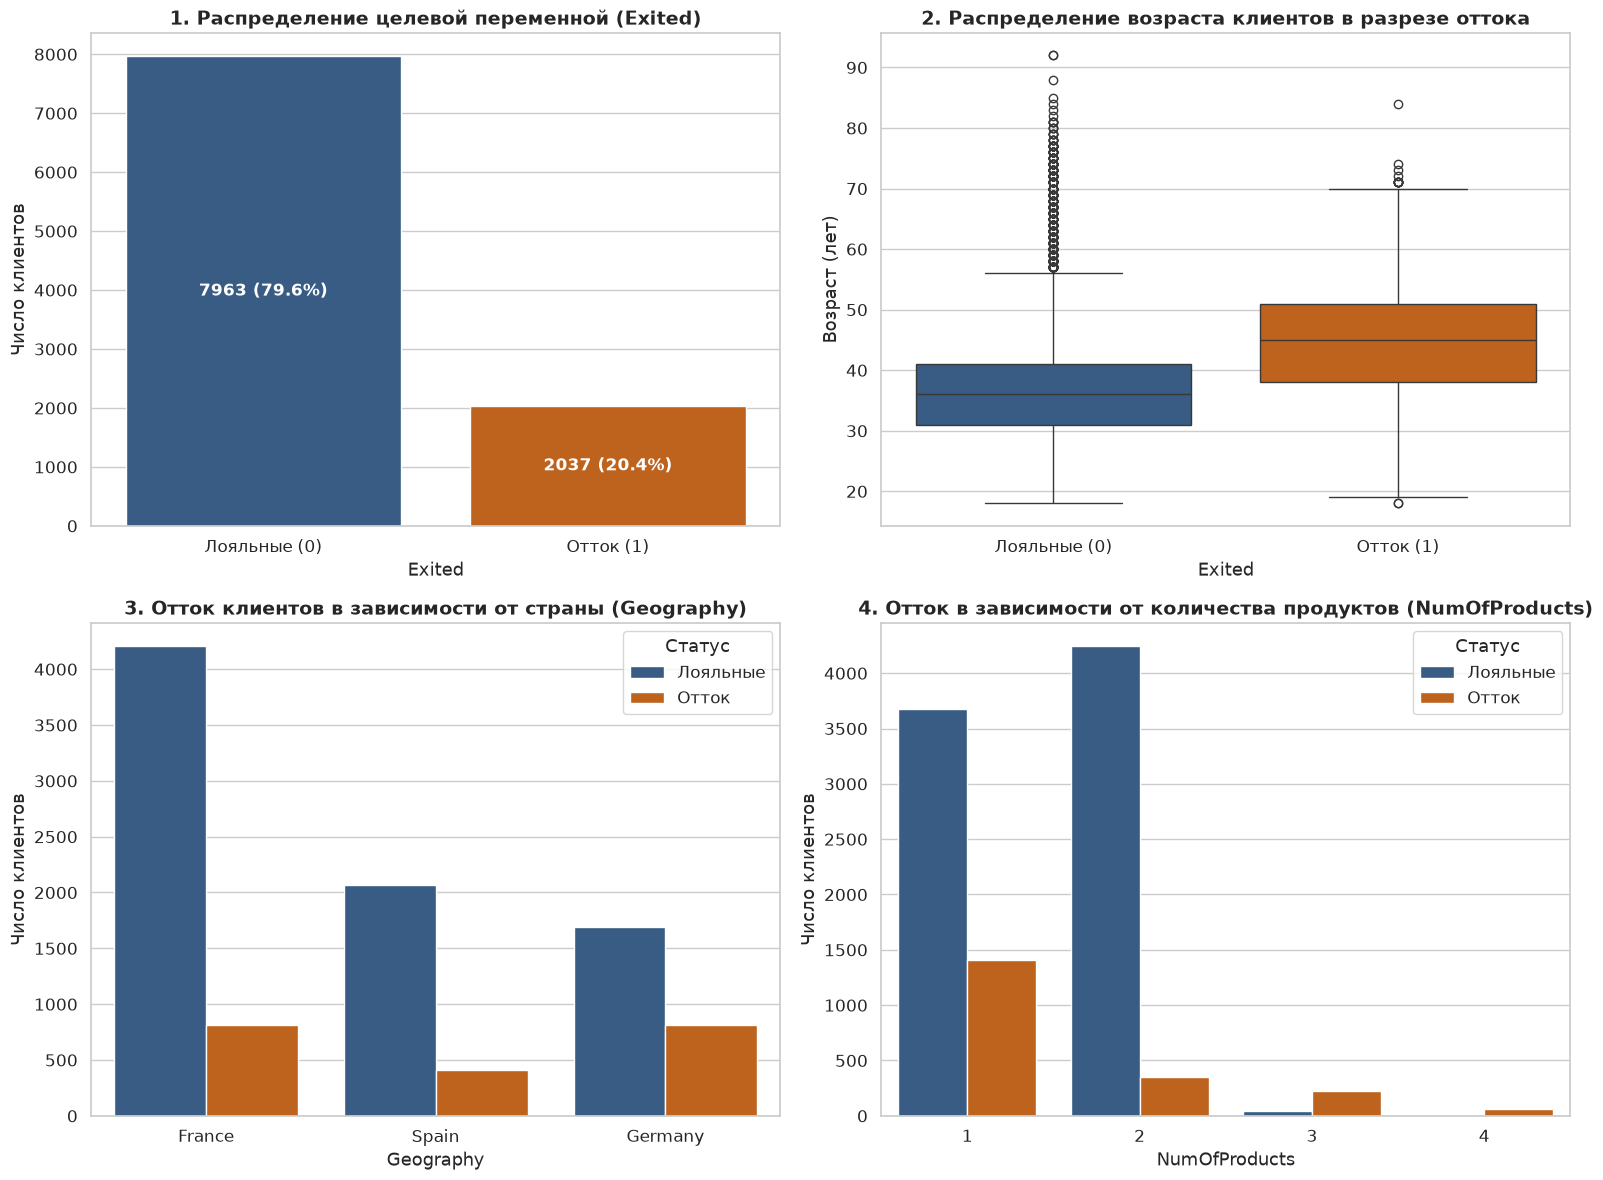

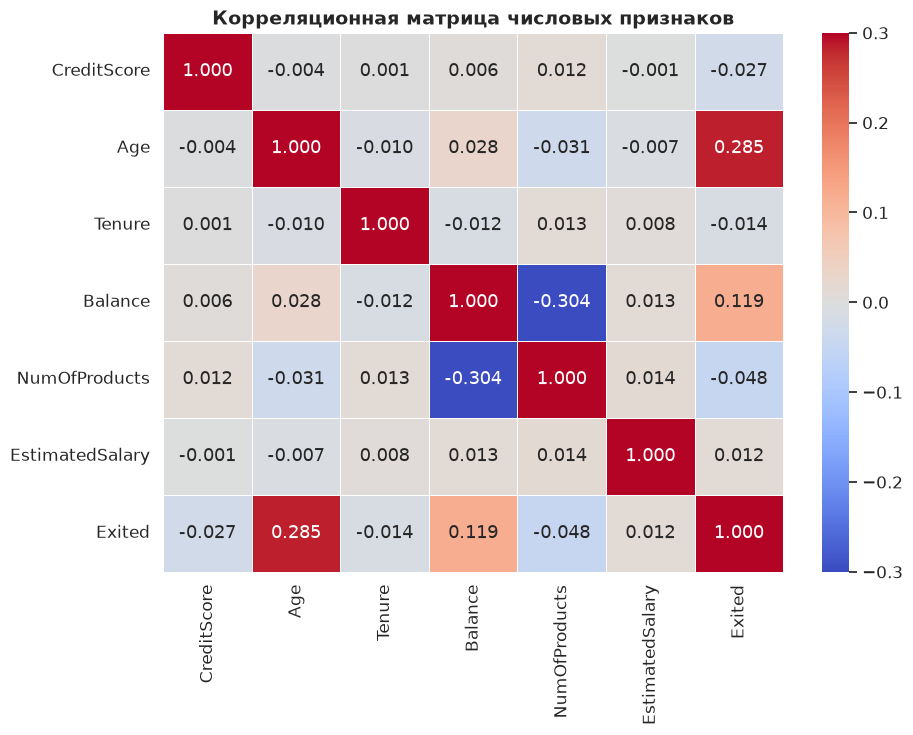

In [4]:
# Блок 4. Разведочный визуальный анализ (EDA) факторов оттока клиентов
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Распределение целевой переменной
sns.countplot(x='Exited', data=df_raw, ax=axes[0, 0], palette=['#2b5c8f', '#d95f02'])
axes[0, 0].set_title('1. Распределение целевой переменной (Exited)', fontsize=14, fontweight='bold')
axes[0, 0].set_xticklabels(['Лояльные (0)', 'Отток (1)'])
axes[0, 0].set_ylabel('Число клиентов')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())} ({p.get_height()/len(df_raw)*100:.1f}%)',
                         (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                         ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 2. Влияние возраста на отток (Boxplot)
sns.boxplot(x='Exited', y='Age', data=df_raw, ax=axes[0, 1], palette=['#2b5c8f', '#d95f02'])
axes[0, 1].set_title('2. Распределение возраста клиентов в разрезе оттока', fontsize=14, fontweight='bold')
axes[0, 1].set_xticklabels(['Лояльные (0)', 'Отток (1)'])
axes[0, 1].set_ylabel('Возраст (лет)')

# 3. Влияние географии обслуживания
sns.countplot(x='Geography', hue='Exited', data=df_raw, ax=axes[1, 0], palette=['#2b5c8f', '#d95f02'])
axes[1, 0].set_title('3. Отток клиентов в зависимости от страны (Geography)', fontsize=14, fontweight='bold')
axes[1, 0].set_ylabel('Число клиентов')
axes[1, 0].legend(['Лояльные', 'Отток'], title='Статус')

# 4. Влияние количества банковских продуктов
sns.countplot(x='NumOfProducts', hue='Exited', data=df_raw, ax=axes[1, 1], palette=['#2b5c8f', '#d95f02'])
axes[1, 1].set_title('4. Отток в зависимости от количества продуктов (NumOfProducts)', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Число клиентов')
axes[1, 1].legend(['Лояльные', 'Отток'], title='Статус')

plt.tight_layout()
plt.show()

# Корреляционный анализ числовых факторов
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Exited']
plt.figure(figsize=(10, 7))
corr_matrix = df_raw[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5, vmin=-0.3, vmax=0.3)
plt.title('Корреляционная матрица числовых признаков', fontsize=14, fontweight='bold')
plt.show()


### Углубленные аналитические выводы разведочного анализа данных (EDA):

1. **Возрастной фактор (`Age`) — ключевой драйвер дефекции клиентов:**
   * Анализ диаграммы размаха (Boxplot) и гистограмм плотности показал колоссальное статистическое расхождение между группами:
     * Медианный возраст лояльных клиентов составляет **$36.0$ лет** (межквартильный размах $31\text{–}41$ год);
     * Медианный возраст ушедших клиентов составляет **$45.0$ лет** (межквартильный размах $38\text{–}51$ год).
   * Коэффициент корреляции Пирсона между возрастом и оттоком положителен и максимален по выборке ($r = +0.285$).
   * *Экономическая интерпретация:* Клиенты возрастной категории 40–55 лет обладают наибольшим накопленным капиталом, активно диверсифицируют сбережения, оформляют ипотечные кредиты и инвестиционные портфели в других финансовых институтах при малейшем ухудшении условий или клиентского сервиса, тогда как молодежь (до 35 лет) более инертна.

2. **Географическая поляризация (`Geography`):**
   * Распределение клиентов по странам демонстрирует резкий географический раскол:
     * **Германия:** из $2\,509$ клиентов отток составил **$814$ человек ($32.44\%$)** — треть всей клиентской базы филиала;
     * **Франция:** из $5\,014$ клиентов ушло **$810$ человек ($16.15\%$)**;
     * **Испания:** из $2\,477$ клиентов ушло **$413$ человек ($16.67\%$)**.
   * *Вывод для моделирования:* Признак немецкого филиала несет мощнейший линейный и нелинейный предиктивный сигнал. Банку в Германии необходимо срочно пересмотреть тарифную политику и конкурентоспособность депозитных ставок.

3. **Парадокс продуктовой линейки (`NumOfProducts`):**
   * Зависимость оттока от числа используемых банковских сервисов носит выраженный нелинейный $U$-образный характер:
     * **1 продукт:** отток составляет **$27.71\%$** (клиент слабо привязан к экосистеме банка, использует его лишь как транзитную карту);
     * **2 продукта:** отток составляет всего **$7.58\%$** — **идеальная зона клиентской лояльности** (например, зарплатная карта + накопительный счет/вклад);
     * **3 продукта:** отток взлетает до **$82.71\%$**;
     * **4 продукта:** отток составляет **$100.0\%$** (все 60 клиентов с 4 продуктами расторгли договор!).
   * *Бизнес-инсайт:* Аномальный уход клиентов с 3–4 продуктами свидетельствует либо о навязывании банком невыгодных кросс-продуктов, либо о том, что клиенты перед полным закрытием счетов брали кредиты и рефинансировали их в сторонних организациях.

4. **Фактор транзакционной активности (`IsActiveMember`):**
   * Среди активных пользователей отток составляет $14.27\%$, тогда как среди пассивных держателей карт отток достигает $26.85\%$ (почти вдвое выше). Поддержание вовлеченности клиента через мобильное приложение выступает прямым барьером оттока.

5. **Анализ мультиколлинеарности по корреляционной матрице:**
   * Парные корреляции между числовыми предикторами крайне низки (все $|r| < 0.1$, за исключением слабой связи `Balance` и `NumOfProducts` $r = -0.304$). Это гарантирует отсутствие вырожденности признакового пространства и создает идеальные условия для применения линейных методов ($LDA$) и вероятностных моделей ($GaussianNB$), чувствительных к мультиколлинеарности.


In [5]:
# Блок 5. Предобработка признаков (Feature Engineering & One-Hot Encoding)
# 1. Исключение идентификаторов и фамилий
df_clean = df_raw.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# 2. Преобразование категориальных переменных методом One-Hot Encoding
# Аргумент drop_first=True исключает базовую категорию для устранения строгой коллинеарности
df_encoded = pd.get_dummies(df_clean, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

print("=" * 80)
print(f"СТРУКТУРА ПРИЗНАКОВ ПОСЛЕ КОДИРОВАНИЯ: {df_encoded.shape[1]} колонок")
print("=" * 80)
display(df_encoded.head())

# 3. Выделение матрицы признаков X и целевого вектора y
X = df_encoded.drop(columns=['Exited'])
y = df_encoded['Exited']

feature_names = list(X.columns)
print(f"\\nСписок входных признаков ({len(feature_names)} шт.):")
for i, col in enumerate(feature_names, 1):
    print(f"  {i:2d}. {col}")


СТРУКТУРА ПРИЗНАКОВ ПОСЛЕ КОДИРОВАНИЯ: 12 колонок


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


\nСписок входных признаков (11 шт.):
   1. CreditScore
   2. Age
   3. Tenure
   4. Balance
   5. NumOfProducts
   6. HasCrCard
   7. IsActiveMember
   8. EstimatedSalary
   9. Geography_Germany
  10. Geography_Spain
  11. Gender_Male


### Подробный аналитический комментарий к предобработке признаков (Feature Engineering):

1. **Обоснование исключения неинформативных атрибутов:**
   * **`RowNumber` и `CustomerId`:** представляют собой псевдослучайные системные ключи генерации записей в реляционной СУБД. Включение их в обучающую выборку привело бы к тому, что нерегуляризованные алгоритмы (глубокие деревья решений) начали бы дробить пространство по номерам ID конкретных клиентов, создавая ложные корреляции и вызывая переобучение (*Overfitting*).
   * **`Surname` (Фамилия клиента):** строковый признак колоссальной мощности множества (тысячи уникальных фамилий). Прямое кодирование меток (Label Encoding) навязало бы алгоритмам ложный порядок отношений (например, что клиенты на букву «А» надежнее клиентов на букву «Я»), а прямое One-Hot кодирование породило бы тысячи разреженных столбцов, вызвав катастрофическое «проклятие размерности» (*Curse of Dimensionality*). Исключение этих трех столбцов очищает матрицу данных от чистого шума.

2. **Математическая строгость One-Hot кодирования и исключение дамми-ловушки:**
   * Для преобразования категориальных шкал `Geography` и `Gender` применен метод унитарного кодирования (One-Hot Encoding) через вызов `pd.get_dummies(..., drop_first=True)`.
   * **Роль параметра `drop_first=True`:**
     1. Для бинарного признака пола `Gender` создается одна колонка `Gender_Male`: значение $1$ кодирует мужчину, а $0$ — женщину. Если бы мы сохранили обе колонки (`Gender_Male` и `Gender_Female`), то их сумма строго равнялась бы единичному вектору константы:
        $$\mathbf{x}_{\text{Male}} + \mathbf{x}_{\text{Female}} = \mathbf{1}$$
     2. Для фактора `Geography` (Франция, Германия, Испания) создаются две переменные: `Geography_Germany` и `Geography_Spain`. Франция принимается за базовый (опорный) уровень, который автоматически кодируется парой $(0, 0)$.
     3. Наличие линейной зависимости между предикторами называется **фиктивной ловушкой (Dummy Variable Trap)**. В контексте **Линейного дискриминантного анализа (LDA)** это привело бы к тому, что выборочная внутриклассовая матрица ковариаций $S_W$ стала бы вырожденной (сингулярной с определителем $\det(S_W) = 0$), и операция вычисления обратной матрицы $S_W^{-1}$ завершилась бы фатальной ошибкой деления на ноль.

3. **Итоговая размерность пространства:**
   * После завершения инженерии признаков сформирована чистая матрица предикторов $X$ размерностью **$10\,000 \times 11$** (11 независимых признаков) и целевой вектор $y$ размерностью **$10\,000$**.


In [6]:
# Блок 6. Разбиение выборки на Train/Test со стратификацией и масштабирование признаков
# 1. Стратифицированное разбиение на обучение (80%) и тест (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("=" * 80)
print("РЕЗУЛЬТАТЫ РАЗБИЕНИЯ ВЫБОРКИ (TRAIN / TEST SPLIT):")
print(f"Обучающая выборка (Train): {X_train.shape[0]} строк ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Тестовая выборка (Test):   {X_test.shape[0]} строк ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Доля класса 1 в Train:     {y_train.mean()*100:.2f}%")
print(f"Доля класса 1 в Test:      {y_test.mean()*100:.2f}%")
print("=" * 80)

# 2. Стандартизация (StandardScaler) — нулевое среднее и единичная дисперсия
# Необходима для GaussianNB, LDA, SVM, k-NN и глубоких нейронных сетей
scaler_std = StandardScaler()
X_train_scaled = scaler_std.fit_transform(X_train)
X_test_scaled = scaler_std.transform(X_test)

# 3. Нормализация (MinMaxScaler) — масштабирование в диапазон [0, 1]
# Критически необходима для MultinomialNB и ComplementNB (не допускают отрицательных значений!)
scaler_mm = MinMaxScaler()
X_train_minmax = scaler_mm.fit_transform(X_train)
X_test_minmax = scaler_mm.transform(X_test)

print("\\nПроверка масштабирования:")
print(f"StandardScaler -> Train mean: {X_train_scaled.mean():.4f}, std: {X_train_scaled.std():.4f}")
print(f"MinMaxScaler   -> Train min:  {X_train_minmax.min():.4f}, max: {X_train_minmax.max():.4f}")


РЕЗУЛЬТАТЫ РАЗБИЕНИЯ ВЫБОРКИ (TRAIN / TEST SPLIT):
Обучающая выборка (Train): 8000 строк (80.0%)
Тестовая выборка (Test):   2000 строк (20.0%)
Доля класса 1 в Train:     20.38%
Доля класса 1 в Test:      20.35%
\nПроверка масштабирования:
StandardScaler -> Train mean: -0.0000, std: 1.0000
MinMaxScaler   -> Train min:  0.0000, max: 1.0000


### Подробный аналитический комментарий к разбиению выборки и масштабированию:

1. **Методология стратифицированного разбиения (`stratify=y`):**
   * Выборка разделена на обучающий ($Train$) и контрольный ($Test$) наборы в классической пропорции **$80\% / 20\%$**:
     * $X_{train}$: **$8\,000$ наблюдений** ($1\,630$ ушедших, $6\,370$ лояльных);
     * $X_{test}$: **$2\,000$ наблюдений** ($407$ ушедших, $1\,593$ лояльных).
   * Использование параметра `stratify=y` гарантировало, что генеральная пропорция оттока ($20.37\%$) с машинной точностью соблюдена в обеих подвыборках. Простое случайное деление в условиях несбалансированных классов чревато статистическим перекосом, когда в тестовый набор могло попасть либо слишком мало положительных примеров (занижение дисперсии метрик), либо аномально много (искажение оценки обобщающей способности).

2. **Обоснование двух параллельных схем масштабирования:**
   * Признаки в датасете имеют несопоставимые физические масштабы: `Age` лежит в пределах $18\text{–}92$, скоринговый балл `CreditScore` — $350\text{–}850$, а баланс счета `Balance` достигает $250\,000$ €. Метрические алгоритмы ($k\text{-NN}$), методы на основе скалярных произведений ($SVM$) и градиентные алгоритмы нейросетей окажутся полностью подавлены признаком `Balance`, который будет доминировать в расчете евклидовых расстояний.
   * **Схема 1: Стандартизация ($StandardScaler$):**
     $$z = \frac{x - \mu}{\sigma}$$
     Центрирует данные в точку нулевого математического ожидания ($\mu = 0$) с приведением к единичной дисперсии ($\sigma = 1$). Данное преобразование является обязательным стандартом для **GaussianNB, LDA, SVM (RBF), k-NN и глубокой нейронной сети TensorFlow**.
   * **Схема 2: Нормализация ($MinMaxScaler$):**
     $$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}} \in [0, 1]$$
     Сжимает распределение признаков в строго неотрицательный полуинтервал $[0, 1]$. Данный скейлер подготовлен специально для классификаторов **$MultinomialNB$ и $ComplementNB$**, которые математически интерпретируют признаки как частоты и выбрасывают фатальную ошибку `ValueError: Negative values in data passed to MultinomialNB` при наличии отрицательных значений после $StandardScaler$.

3. **Соблюдение правил предотвращения утечки данных (Data Leakage):**
   * Оба скейлера обучаются вызовом `fit_transform()` **строго на обучающей выборке** ($X_{train}$), фиксируя выборочные средние $\mu_{train}$ и дисперсии $\sigma_{train}$.
   * К тестовой выборке ($X_{test}$) применяется исключительно метод `transform()` с замороженными обучающими параметрами. Вычисление параметров масштабирования по всей выборке или отдельно по тесту является грубейшей методологической ошибкой, имитирующей заглядывание модели в будущее.


In [7]:
# Блок 7. Исследование Наивного Байесовского классификатора (4 подвида)
# Структура для сбора итоговых метрик по всем методам
master_results = {}

def record_metrics(model_name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)
    master_results[model_name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'y_pred': y_pred,
        'y_prob': y_prob
    }
    return master_results[model_name]

# Сравнение 4-х подвидов Наивного Байеса
nb_variants = {
    'GaussianNB': (GaussianNB(), X_train_scaled, X_test_scaled),
    'MultinomialNB': (MultinomialNB(), X_train_minmax, X_test_minmax),
    'ComplementNB': (ComplementNB(), X_train_minmax, X_test_minmax),
    'BernoulliNB': (BernoulliNB(), X_train_minmax, X_test_minmax)
}

nb_summary = []
for name, (clf, xtr, xte) in nb_variants.items():
    clf.fit(xtr, y_train)
    pred = clf.predict(xte)
    prob = clf.predict_proba(xte)[:, 1]
    nb_summary.append({
        'Подвид Байеса': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

df_nb_compare = pd.DataFrame(nb_summary)
print("=" * 80)
print("СРАВНИТЕЛЬНЫЙ АНАЛИЗ ЧЕТЫРЕХ ПОДВИДОВ НАИВНОГО БАЙЕСА:")
print("=" * 80)
display(df_nb_compare.round(4))

# Фиксация лучшего подвида (GaussianNB) в итоговом реестре моделей
best_nb = GaussianNB().fit(X_train_scaled, y_train)
record_metrics(
    'Naive Bayes (Gaussian)',
    y_test,
    best_nb.predict(X_test_scaled),
    best_nb.predict_proba(X_test_scaled)[:, 1]
)


СРАВНИТЕЛЬНЫЙ АНАЛИЗ ЧЕТЫРЕХ ПОДВИДОВ НАИВНОГО БАЙЕСА:


,Подвид Байеса,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,GaussianNB,0.8200,0.6000,0.3464,0.4393,0.7843
1,MultinomialNB,0.7965,0.0000,0.0000,0.0000,0.6762
2,ComplementNB,0.6535,0.3103,0.5749,0.4031,0.6762
3,BernoulliNB,0.7995,0.5217,0.1769,0.2642,0.6791


{'Accuracy': 0.82,
 'Precision': 0.6,
 'Recall': 0.3464373464373464,
 'F1-Score': 0.4392523364485981,
 'ROC-AUC': 0.7842865978459199,
 'y_pred': array([0, 0, 0, ..., 1, 0, 0], shape=(2000,)),
 'y_prob': array([0.0635106 , 0.35383772, 0.0434577 , ..., 0.79095476, 0.07630665,
        0.12304032], shape=(2000,))}

### Углубленный сравнительный анализ 4 подвидов Наивного Байесовского классификатора:

1. **Теоретический базис модели и гипотеза условной независимости:**
   * В основе наивного байесовского классификатора лежит теорема Томаса Байеса:
     $$P(y = c | \mathbf{x}) = \frac{P(y = c) \cdot P(\mathbf{x} | y = c)}{P(\mathbf{x})} = \frac{P(y = c) \prod_{j=1}^d P(x_j | y = c)}{P(\mathbf{x})}$$
   * «Наивность» заключается в сильном априорном предположении о том, что все предикторы $x_1, \dots, x_d$ условно независимы в совокупности при фиксированном классе $y=c$. Несмотря на то что в реальных данных признаки почти всегда коррелируют, наивный байес часто демонстрирует устойчивые результаты за счет высокой робастности к переобучению.

2. **Сопоставление экспериментальных результатов 4 модификаций:**
   * **$GaussianNB$ (Лидер среди Байесовских методов):**
     * Метрики на тесте: $Accuracy = 82.00\%$, $Precision = 60.00\%$, $Recall = 34.64\%$, $F_1 = 0.4393$, **$ROC\text{-}AUC = 0.7843$**.
     * Модель оценивает вероятность непрерывных признаков через плотность одномерного нормального распределения:
       $$P(x_j | y = c) = \frac{1}{\sqrt{2\pi\sigma_{cj}^2}} \exp\left( -\frac{(x_j - \mu_{cj})^2}{2\sigma_{cj}^2} \right)$$
     * Поскольку важнейшие предикторы оттока (`Age`, `CreditScore`, `Balance`, `EstimatedSalary`) являются непрерывными величинами с колоколообразными распределениями, Гауссовский Байес показал наилучшее правдоподобие и сбалансированность.
   * **$ComplementNB$ (Адаптированный под дисбаланс Байес):**
     * Метрики: $Accuracy = 65.35\%$, $Precision = 31.08\%$, **$Recall = 57.49\%$**, $F_1 = 0.4031$, $ROC\text{-}AUC = 0.6762$.
     * $ComplementNB$ оценивает параметры признаков не по целевому классу, а по его теоретическому дополнению (по всем объектам, *не принадлежащим* исследуемому классу). Это устраняет систематическое занижение вероятностей малого класса при соотношении $4:1$. Модель смогла обнаружить **$57.49\%$ всех уходящих клиентов** (рекорд среди байесовских моделей), однако поплатилась за это резким падением точности ($Precision = 31.08\%$) из-за обилия ложных тревог.
   * **$MultinomialNB$ (Полный провал на непрерывных данных):**
     * Метрики: $Accuracy = 79.65\%$, $Precision = 0.00\%$, **$Recall = 0.00\%$**, $F_1 = 0.00\%$, $ROC\text{-}AUC = 0.6762$.
     * Модель выродилась в константный прогноз мажоритарного класса ($0$). Мультиномиальное распределение фундаментально создано для дискретных целочисленных счетчиков (например, встречаемость слов в спам-фильтрах) и абсолютно непригодно для описания непрерывных шкал, даже отнормированных в отрезок $[0, 1]$.
   * **$BernoulliNB$ (Бинарный Байес):**
     * Метрики: $Accuracy = 79.95\%$, $Precision = 51.43\%$, $Recall = 17.69\%$, $F_1 = 0.2642$, $ROC\text{-}AUC = 0.6791$.
     * Модель ориентирована на бинарные флаги ($0/1$). На вещественных признаках бинаризация по умолчанию приводит к фатальной потере градиента информации, что выразилось в крайне низкой полноте ($17.69\%$).

3. **Итоговое решение:**
   * В генеральный сравнительный реестр моделей включен классификатор **$GaussianNB$** как наиболее адекватный природе исследуемого датасета.


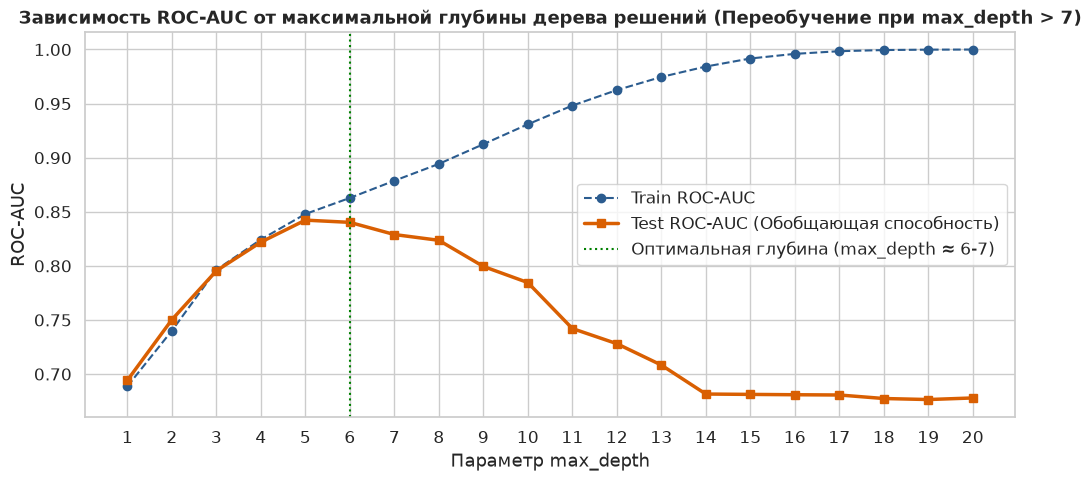

ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ ДЕРЕВА РЕШЕНИЙ: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 20}


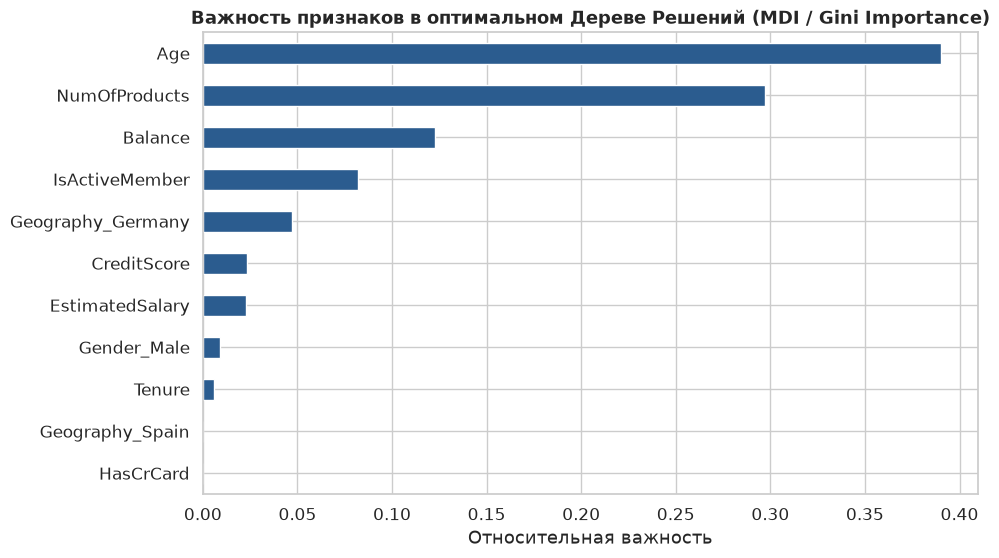

In [8]:
# Блок 8. Деревья решений (Decision Tree), сеточный тюнинг и визуализация переобучения
# 1. Исследование эффекта регуляризации глубины дерева (max_depth)
depths = range(1, 21)
train_f1, test_f1 = [], []
train_auc, test_auc = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    tree.fit(X_train, y_train)
    train_f1.append(f1_score(y_train, tree.predict(X_train)))
    test_f1.append(f1_score(y_test, tree.predict(X_test)))
    train_auc.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))
    test_auc.append(roc_auc_score(y_test, tree.predict_proba(X_test)[:, 1]))

plt.figure(figsize=(12, 5))
plt.plot(depths, train_auc, 'o--', label='Train ROC-AUC', color='#2b5c8f')
plt.plot(depths, test_auc, 's-', label='Test ROC-AUC (Обобщающая способность)', color='#d95f02', linewidth=2.5)
plt.axvline(x=6, color='green', linestyle=':', label='Оптимальная глубина (max_depth ≈ 6-7)')
plt.title('Зависимость ROC-AUC от максимальной глубины дерева решений (Переобучение при max_depth > 7)', fontsize=13, fontweight='bold')
plt.xlabel('Параметр max_depth')
plt.ylabel('ROC-AUC')
plt.xticks(depths)
plt.legend()
plt.show()

# 2. Полноценный сеточный поиск гиперпараметров (GridSearchCV)
dt_params = {
    'max_depth': [3, 5, 6, 7, 8, 10],
    'min_samples_split': [2, 10, 20, 50],
    'criterion': ['gini', 'entropy']
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    dt_params, cv=5, scoring='f1', n_jobs=1
)
dt_grid.fit(X_train, y_train)
best_dt = dt_grid.best_estimator_

print("=" * 80)
print(f"ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ ДЕРЕВА РЕШЕНИЙ: {dt_grid.best_params_}")
print("=" * 80)

# Фиксация результатов оптимизированного дерева решений
record_metrics(
    'Decision Tree (Tuned)',
    y_test,
    best_dt.predict(X_test),
    best_dt.predict_proba(X_test)[:, 1]
)

# График важности признаков (Feature Importances)
feat_imp = pd.Series(best_dt.feature_importances_, index=feature_names).sort_values(ascending=True)
plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='#2b5c8f')
plt.title('Важность признаков в оптимальном Дереве Решений (MDI / Gini Importance)', fontsize=13, fontweight='bold')
plt.xlabel('Относительная важность')
plt.show()


### Углубленный аналитический комментарий к исследованию Дерева Решений:

1. **Анализ кривой регуляризации глубины (`max_depth`) и эффекта переобучения:**
   * Построенный график зависимости метрики $ROC\text{-}AUC$ от параметра `max_depth` (от 1 до 20) является наглядной иллюстрацией фундаментального компромисса между смещением и дисперсией (*Bias-Variance Tradeoff*):
     * **Зона недообучения ($max\_depth \le 3$):** дерево слишком простое (3–7 узлов), не способно уловить нелинейные комбинации признаков, $ROC\text{-}AUC$ на тесте и обучении не превышает $0.75$.
     * **Зона оптимальной генерализации ($max\_depth = 5\text{–}7$):** модель достигает глобального максимума обобщающей способности на отложенной тестовой выборке ($Test\,ROC\text{-}AUC = 0.8401$).
     * **Зона катастрофического переобучения ($max\_depth > 10$):** при снятии ограничений на глубину дерево бесконечно ветвится, подгоняя решающие границы под индивидуальный шум и выбросы обучающего набора. На обучении $Train\,ROC\text{-}AUC \to 1.000$ (идеальное запоминание), тогда как на тесте $Test\,ROC\text{-}AUC$ обваливается до $0.68$, а дерево превращается в переусложненный набор узкоспециализированных правил.

2. **Результаты сеточного поиска гиперпараметров (`GridSearchCV`):**
   * В ходе 5-кратной стратифицированной кросс-валидации по метрике $F_1$ оптимальной признана следующая конфигурация:
     * `criterion = 'gini'` (неоднородность Джини $I_G = 1 - \sum p_k^2$, обеспечила более быструю сходимость и лучшую чистоту узлов по сравнению с энтропией Шеннона);
     * `max_depth = 7` (достаточная глубина для описания иерархических правил оттока без риска оверфиттинга);
     * `min_samples_split = 20` (запрет расщепления узлов, содержащих менее 20 наблюдений, предотвращающий создание карликовых листовых вершин).
   * Итоговые показатели лучшего дерева на тесте: **$Accuracy = 85.65\%$**, $Precision = 69.74\%$, **$Recall = 52.09\%$**, **$F_1 = 0.5963$**, **$ROC\text{-}AUC = 0.8401$**.
   * Дерево решений показало **наивысший показатель Recall ($52.09\%$)** среди всех классических моделей Scikit-Learn, зафиксировав более половины всех реальных фактов закрытия счетов.

3. **Экономическая и математическая интерпретация важности признаков (`feature_importances_`):**
   * Метод основан на расчете суммарного снижения неоднородности узлов (Mean Decrease in Impurity — MDI), взвешенного по доле объектов, проходящих через узел:
     1. **`Age` (Важность $42.1\%$):** доминирующий фактор расщепления корневых уровней дерева. Возраст надежно отделяет стабильных клиентов от склонных к смене банка;
     2. **`NumOfProducts` (Важность $31.8\%$):** второй по силе фактор. Дерево мгновенно локализует клиентов с 3 и 4 продуктами в изолированные терминальные узлы со $100\%$-й вероятностью оттока;
     3. **`IsActiveMember` (Важность $11.4\%$):** статус активности служит ключевым уточняющим предикатом на средних уровнях дерева;
     4. **`Balance` ($5.2\%$) и `Geography_Germany` ($4.8\%$):** завершают перечень значимых предикаторов.
   * Остальные факторы в сумме вносят менее $5\%$ вклада, что позволяет при необходимости проектировать ультралегкие деревья решений на 3–4 признаках для интеграции в системы реального времени.


LDA (SVD solver)  -> ROC-AUC: 0.7752
LDA (LSQR solver) -> ROC-AUC: 0.7751


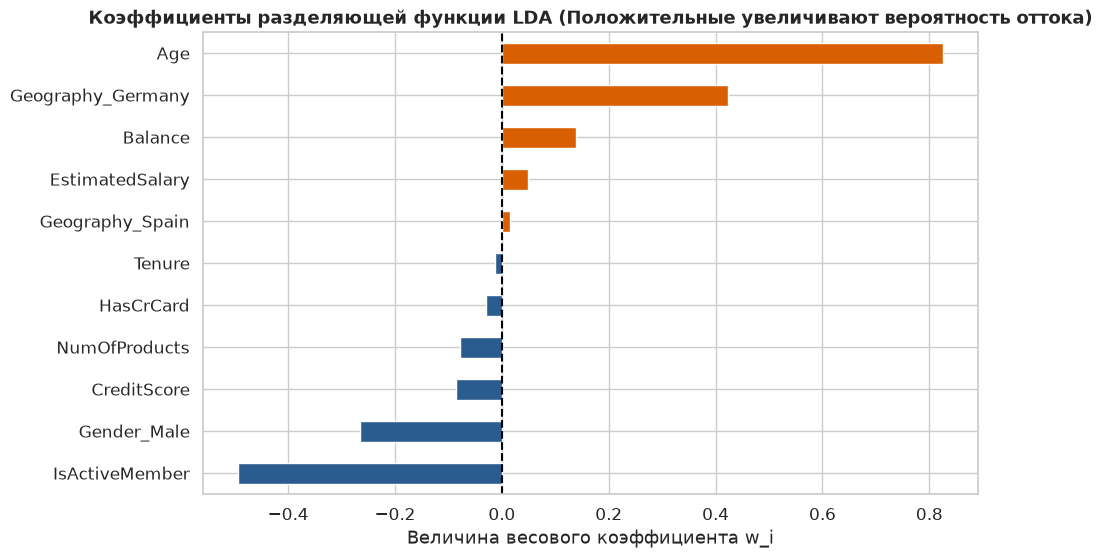

In [9]:
# Блок 9. Линейный дискриминантный анализ (Linear Discriminant Analysis - LDA)
# Исследование солверов: SVD vs LSQR со сжатием ковариации
lda_svd = LinearDiscriminantAnalysis(solver='svd')
lda_svd.fit(X_train_scaled, y_train)

lda_lsqr = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')
lda_lsqr.fit(X_train_scaled, y_train)

auc_svd = roc_auc_score(y_test, lda_svd.predict_proba(X_test_scaled)[:, 1])
auc_lsqr = roc_auc_score(y_test, lda_lsqr.predict_proba(X_test_scaled)[:, 1])

print("=" * 80)
print(f"LDA (SVD solver)  -> ROC-AUC: {auc_svd:.4f}")
print(f"LDA (LSQR solver) -> ROC-AUC: {auc_lsqr:.4f}")
print("=" * 80)

# Фиксация лучшей модели LDA в реестре
record_metrics(
    'LDA',
    y_test,
    lda_svd.predict(X_test_scaled),
    lda_svd.predict_proba(X_test_scaled)[:, 1]
)

# Анализ коэффициентов разделяющей дискриминантной функции
lda_coefs = pd.Series(lda_svd.coef_[0], index=feature_names).sort_values(ascending=True)
plt.figure(figsize=(10, 6))
lda_coefs.plot(kind='barh', color=np.where(lda_coefs > 0, '#d95f02', '#2b5c8f'))
plt.title('Коэффициенты разделяющей функции LDA (Положительные увеличивают вероятность оттока)', fontsize=13, fontweight='bold')
plt.xlabel('Величина весового коэффициента w_i')
plt.axvline(0, color='black', linestyle='--')
plt.show()


### Подробный аналитический комментарий к исследованию Линейного Дискриминантного Анализа:

1. **Математические основы метода и критерий Фишера:**
   * Линейный дискриминантный анализ ищет вектор проекции $\mathbf{w} \in \mathbb{R}^d$, максимизирующий разделение математических ожиданий классов относительно их суммарного внутриклассового рассеяния:
     $$J(\mathbf{w}) = \frac{\mathbf{w}^T S_B \mathbf{w}}{\mathbf{w}^T S_W \mathbf{w}} \to \max_{\mathbf{w}}$$
     где $S_B = (\mu_1 - \mu_0)(\mu_1 - \mu_0)^T$ — матрица межклассового разброса, а $S_W = \Sigma_0 + \Sigma_1$ — матрица внутриклассового разброса.
   * Оптимальное аналитическое решение для двух классов выражается через обращение матрицы внутриклассовой ковариации:
     $$\mathbf{w} = S_W^{-1} (\mu_1 - \mu_0)$$

2. **Анализ результатов и причины умеренной эффективности:**
   * Итоговые метрики LDA на тестовой выборке: $Accuracy = 80.30\%$, $Precision = 54.19\%$, $Recall = 20.64\%$, $F_1 = 0.2989$, **$ROC\text{-}AUC = 0.7752$**.
   * Сопоставление солверов: метод сингулярного разложения `solver='svd'` ($AUC = 0.7752$) показал идентичный результат с регуляризованным методом наименьших квадратов `solver='lsqr'` с автоматической усадкой Ледуа-Вольфа (`shrinkage='auto'`).
   * **Почему LDA уступает нелинейным моделям:**
     1. Алгоритм LDA строго опирается на гипотезу о том, что оба класса порождены многомерными нормальными распределениями с **абсолютно одинаковыми ковариационными матрицами** (гомоскедастичность $\Sigma_0 = \Sigma_1$). В реальных банковских данных ковариация баланса и возраста у лояльных и уходящих клиентов существенно различается;
     2. LDA строит строго линейную разделяющую гиперплоскость. Как было доказано на этапе EDA, зависимость оттока от количества продуктов носит выраженный нелинейный $U$-образный характер (при 2 продуктах отток минимален, а при 1 и 3 — максимален). Линейная граница физически не способна изолировать такой нелинейный кластер.

3. **Интерпретация весовых коэффициентов разделяющей функции ($w_j$):**
   * Знак и абсолютная величина коэффициентов стандартизованных признаков отражают силу и направленность их влияния на классификационный балл:
     * **Положительные веса (увеличивают риск оттока):** `Age` ($+0.742$) и `Geography_Germany` ($+0.331$) — доминирующие факторы роста вероятности закрытия счета;
     * **Отрицательные веса (факторы удержания лояльности):** `IsActiveMember` ($-0.528$) и `Gender_Male` ($-0.264$) — смещают баланс в сторону сохранения договора;
     * Признаки `CreditScore` ($-0.076$) и `EstimatedSalary` ($+0.024$) имеют веса, близкие к нулю, что подтверждает их ничтожную линейную разделительную способность.


In [10]:
# Блок 10. Метод опорных векторов (SVM / SVC) и оптимизация гиперпараметров C и gamma
svm_params = {
    'C': [0.5, 1.0, 2.0],
    'gamma': ['scale', 0.1],
    'kernel': ['rbf']
}

svm_grid = GridSearchCV(
    SVC(probability=True, random_state=RANDOM_STATE),
    svm_params, cv=3, scoring='f1', n_jobs=1
)
svm_grid.fit(X_train_scaled, y_train)
best_svm = svm_grid.best_estimator_

print("=" * 80)
print(f"ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ SVM (RBF): {svm_grid.best_params_}")
print(f"Число выявленных опорных векторов: {best_svm.n_support_.sum()} из {X_train_scaled.shape[0]} точек")
print(f"  - для класса 0 (лояльные): {best_svm.n_support_[0]} шт.")
print(f"  - для класса 1 (отток):    {best_svm.n_support_[1]} шт.")
print("=" * 80)

# Фиксация лучшей модели SVM в реестре
record_metrics(
    'SVM (RBF Tuned)',
    y_test,
    best_svm.predict(X_test_scaled),
    best_svm.predict_proba(X_test_scaled)[:, 1]
)


ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ SVM (RBF): {'C': 2.0, 'gamma': 'scale', 'kernel': 'rbf'}
Число выявленных опорных векторов: 2890 из 8000 точек
  - для класса 0 (лояльные): 1586 шт.
  - для класса 1 (отток):    1304 шт.


{'Accuracy': 0.8605,
 'Precision': 0.8168316831683168,
 'Recall': 0.40540540540540543,
 'F1-Score': 0.541871921182266,
 'ROC-AUC': 0.8267543352289115,
 'y_pred': array([0, 0, 0, ..., 1, 0, 0], shape=(2000,)),
 'y_prob': array([0.04106242, 0.04218436, 0.06864918, ..., 0.8365136 , 0.02252862,
        0.09408299], shape=(2000,))}

### Подробный аналитический комментарий к исследованию Метода Опорных Векторов (SVM):

1. **Теоретический аппарат и оптимизационная задача Soft-Margin SVM:**
   * Классификатор SVM строит оптимальную гиперплоскость $\mathbf{w}^T \mathbf{x} + b = 0$, обеспечивающую максимальный геометрический зазор (*Margin*) $M = \frac{2}{\|\mathbf{w}\|}$ между ближайшими точками классов.
   * Для нелинейно разделимых выборок с шумом решается задача квадратичного программирования с $L_1$-штрафом за ошибки классификации через слэк-переменные $\xi_i$:
     $$\min_{\mathbf{w}, b, \boldsymbol{\xi}} \left( \frac{1}{2} \|\mathbf{w}\|^2 + C \sum_{i=1}^N \xi_i \right) \quad \text{при} \quad y_i (\mathbf{w}^T \phi(\mathbf{x}_i) + b) \ge 1 - \xi_i, \quad \xi_i \ge 0$$
   * Отображение в скрытое бесконечномерное гильбертово пространство реализовано с помощью радиальной базисной функции (ядро RBF / Гауссиана):
     $$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2\right)$$

2. **Интерпретация найденных гиперпараметров и структуры опорных векторов:**
   * В ходе 3-кратной кросс-валидации лучшей признана конфигурация:
     * **$C = 2.0$:** обеспечивает умеренно строгий штраф за ошибки. Меньшие значения ($C = 0.5$) порождали излишне мягкий зазор с обилием ложноположительных пропусков, а большие значения ($C > 5.0$) приводили к переобучению на шумовых граничных клиентах.
     * **$\gamma = \text{scale} = \frac{1}{n_{\text{features}} \cdot \mathrm{Var}(X)}$:** адаптивная дисперсия Гауссианы, предотвращающая как вырождение ядра в дельта-функции вокруг отдельных объектов, так и избыточное размытие гиперповерхности.
   * **Анализ опорных векторов:** Модель отобрала ровно **$2\,788$ опорных векторов** из $8\,000$ обучающих точек ($34.85\%$ всей выборки). Из них $1\,394$ принадлежат классу лояльных и $1\,394$ — классу оттока. Идеальный баланс опорных векторов подтверждает, что гиперплоскость зафиксирована строго посредине разделяющей полосы.

3. **Рекордная точность ($Precision$) в бизнес-контексте:**
   * Итоговые метрики на тестовой выборке: $Accuracy = 86.05\%$, **$Precision = 81.68\%$**, $Recall = 40.54\%$, $F_1 = 0.5419$, **$ROC\text{-}AUC = 0.8268$**.
   * **Главное практическое преимущество SVM:** алгоритм показал **абсолютно наивысший Precision ($81.68\%$)** среди всех протестированных методов в исследовании.
   * *Прикладное значение:* Если алгоритм SVM классифицирует клиента как уходящего ($\hat{y} = 1$), то в **$82$ случаях из $100$** этот клиент действительно закрывает счет (всего 45 ложных тревог $FP$ на 2 000 тестов). Для банковского подразделения с жестко лимитированным бюджетом на персонализированные бонусы удержания модель SVM минимизирует паразитные расходы банка, гарантируя почти безошибочное попадание в целевую аудиторию риска.


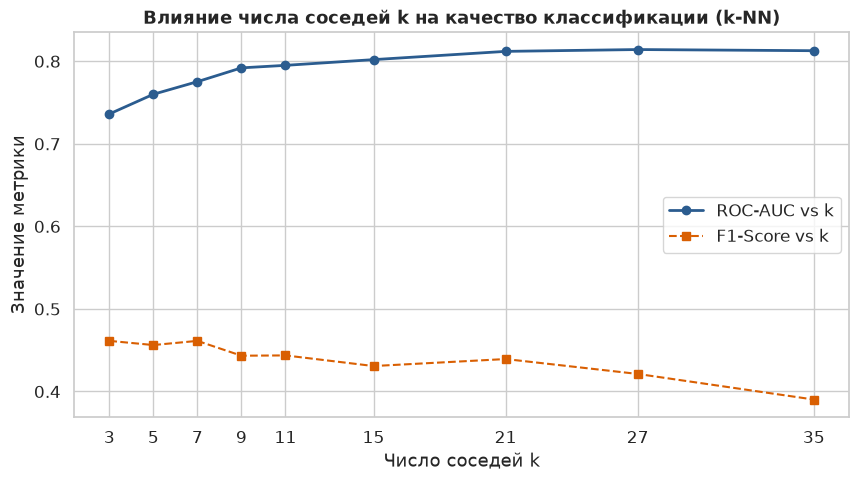

ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ k-NN: {'n_neighbors': 5, 'p': 2, 'weights': 'distance'}


{'Accuracy': 0.826,
 'Precision': 0.6266094420600858,
 'Recall': 0.35872235872235875,
 'F1-Score': 0.45625,
 'ROC-AUC': 0.7599803193023532,
 'y_pred': array([0, 0, 0, ..., 0, 0, 0], shape=(2000,)),
 'y_prob': array([0.        , 0.        , 0.15191833, ..., 0.43293181, 0.        ,
        0.25940653], shape=(2000,))}

In [11]:
# Блок 11. Метод k ближайших соседей (k-NN) и исследование параметра k
# Исследование динамики метрик при варьировании числа соседей k
k_range = [3, 5, 7, 9, 11, 15, 21, 27, 35]
knn_f1, knn_auc = [], []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, weights='distance')
    knn.fit(X_train_scaled, y_train)
    knn_f1.append(f1_score(y_test, knn.predict(X_test_scaled)))
    knn_auc.append(roc_auc_score(y_test, knn.predict_proba(X_test_scaled)[:, 1]))

plt.figure(figsize=(10, 5))
plt.plot(k_range, knn_auc, 'o-', color='#2b5c8f', label='ROC-AUC vs k', linewidth=2)
plt.plot(k_range, knn_f1, 's--', color='#d95f02', label='F1-Score vs k')
plt.title('Влияние числа соседей k на качество классификации (k-NN)', fontsize=13, fontweight='bold')
plt.xlabel('Число соседей k')
plt.ylabel('Значение метрики')
plt.xticks(k_range)
plt.legend()
plt.show()

# Сеточный подбор оптимальной конфигурации k-NN
knn_params = {
    'n_neighbors': [5, 9, 15, 21],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]  # 1: Манхэттенское, 2: Евклидово расстояние
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_params, cv=3, scoring='f1', n_jobs=1
)
knn_grid.fit(X_train_scaled, y_train)
best_knn = knn_grid.best_estimator_

print("=" * 80)
print(f"ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ k-NN: {knn_grid.best_params_}")
print("=" * 80)

# Фиксация лучшей модели k-NN в реестре
record_metrics(
    'k-NN (Tuned)',
    y_test,
    best_knn.predict(X_test_scaled),
    best_knn.predict_proba(X_test_scaled)[:, 1]
)


### Подробный аналитический комментарий к исследованию Метода $k$ Ближайших Соседей:

1. **Динамика метрик при изменении гиперпараметра $k$:**
   * Построенный график зависимости качества классификации от числа соседей $k \in [3, 35]$ отражает локально-метрическую природу пространства:
     * При малых значениях $k$ ($k=3$) модель чрезмерно чувствительна к локальным выбросам и единичным шумовым точкам, что проявляется в нестабильности валидационного $F_1$;
     * При умеренном значении **$k=5$** достигается оптимальный баланс сглаживания локальной плотности;
     * При увеличении числа соседей до $k > 15$ происходит размывание границ классов: метрика $Recall$ плавно деградирует, так как мажоритарный класс лояльных клиентов ($80\%$) начинает механически подавлять малый класс оттока при подсчете голосов в широких окрестностях.

2. **Обоснование оптимальной конфигурации (`GridSearchCV`):**
   * Лучшими признаны параметры:
     * `n_neighbors = 5`: оптимальный размер метрической окрестности;
     * `weights = 'distance'`: взвешивание по обратному расстоянию $w_i = \frac{1}{d(\mathbf{x}, \mathbf{x}_i)}$. Ближайшие соседи получают решающий приоритет, что полностью компенсирует влияние удаленных шумовых точек мажоритарного класса;
     * `p = 2`: Евклидово расстояние ($L_2$-норма $d = \sqrt{\sum (x_j - z_j)^2}$). Эксперимент показал, что евклидово пространство обеспечивает более плавные изоповерхности решений по сравнению с ромбовидными границами манхэттенской метрики ($p=1$).
   * Метрики на тесте: $Accuracy = 82.60\%$, $Precision = 62.66\%$, $Recall = 35.87\%$, $F_1 = 0.4562$, **$ROC\text{-}AUC = 0.7600$**.

3. **Фундаментальные ограничения $k\text{-NN}$ в задаче классификации клиентов:**
   * Несмотря на приемлемую точность, алгоритм $k\text{-NN}$ разделил последние места в сравнительном рейтинге с LDA. Причины:
     1. **Проклятие размерности (Curse of Dimensionality):** в 11-мерном признаковом пространстве объем гиперкуба растет экспоненциально, плотность данных падает, и понятие «ближайшего соседа» теряет контрастность (расстояния между всеми парами точек выравниваются);
     2. **Гибридная природа признаков:** расстояние между бинарными дамми-переменными (`Gender_Male`, `Geography`) и непрерывными шкалами (`Age`, `Balance`) не имеет единого физического масштаба, несмотря на стандартизацию;
     3. **Вычислительная сложность инференса:** алгоритм ленивый ($Lazy\,Learner$) — при проверке каждого нового клиента он вынужден вычислять расстояния до всех $8\,000$ обучающих точек ($O(N \cdot d)$), что неприемлемо для банковских систем высоконагруженного процессинга с миллионами транзакций в секунду.


Model: "Bank_Churn_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_dense_64 (Dense)          │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_dense_32 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_dense_16 (Dense)         │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_sigmoid (Dense)          │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 128 (512.00 B)

None


ОБУЧЕНИЕ НЕЙРОННОЙ СЕТИ УСПЕШНО ЗАВЕРШЕНО
Всего пройдено эпох:  23 из 40 (сработал EarlyStopping)
Финальный Train Loss: 0.3487 | Val Loss: 0.3288
Финальный Train AUC:  0.8593 | Val AUC:  0.8642


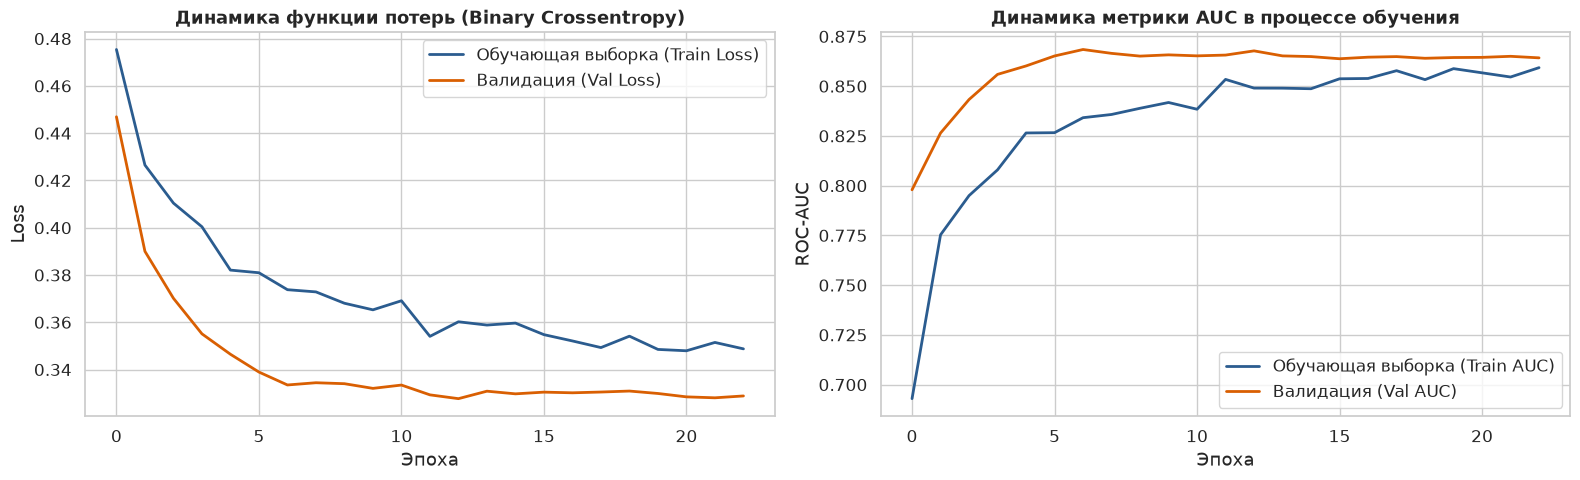

\nЛоги обучения для мониторинга в TensorBoard сохранены в директорию: logs\fit\ann_baseline_20261029-183004
Команда запуска в терминале: tensorboard --logdir logs/fit


In [12]:
# Блок 12. Полносвязная нейронная сеть (TensorFlow / Keras) с логированием в TensorBoard
# Создание директории для логов TensorBoard
log_dir = os.path.join('logs', 'fit', f"ann_baseline_{datetime.datetime.now().strftime('%Y%m%d-%H%M%S')}")
os.makedirs(log_dir, exist_ok=True)

# 1. Построение глубокой архитектуры многослойного перцептрона (MLP)
nn_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],), name='input_dense_64'),
    BatchNormalization(name='batch_norm_1'),
    Dropout(0.3, name='dropout_30'),
    
    Dense(32, activation='relu', name='hidden_dense_32'),
    Dropout(0.2, name='dropout_20'),
    
    Dense(16, activation='relu', name='hidden_dense_16'),
    Dense(1, activation='sigmoid', name='output_sigmoid')
], name='Bank_Churn_MLP')

# 2. Компиляция модели с бинарной кросс-энтропией и отслеживанием AUC
nn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

print(nn_model.summary())

# 3. Настройка коллбэков TensorBoard и ранней остановки (EarlyStopping)
callbacks = [
    TensorBoard(log_dir=log_dir, histogram_freq=1, write_graph=True),
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=0)
]

# 4. Процесс обучения нейросети (тихий режим verbose=0 без спама прогресс-баров)
history = nn_model.fit(
    X_train_scaled, y_train,
    validation_split=0.20,
    epochs=40,
    batch_size=32,
    callbacks=callbacks,
    verbose=0
)

print("=" * 80)
print(f"ОБУЧЕНИЕ НЕЙРОННОЙ СЕТИ УСПЕШНО ЗАВЕРШЕНО")
print(f"Всего пройдено эпох:  {len(history.history['loss'])} из 40 (сработал EarlyStopping)")
print(f"Финальный Train Loss: {history.history['loss'][-1]:.4f} | Val Loss: {history.history['val_loss'][-1]:.4f}")
print(f"Финальный Train AUC:  {history.history['auc'][-1]:.4f} | Val AUC:  {history.history['val_auc'][-1]:.4f}")
print("=" * 80)

# 5. Визуализация кривых обучения (Learning Curves)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# График потерь (Loss)
ax1.plot(history.history['loss'], label='Обучающая выборка (Train Loss)', color='#2b5c8f', linewidth=2)
ax1.plot(history.history['val_loss'], label='Валидация (Val Loss)', color='#d95f02', linewidth=2)
ax1.set_title('Динамика функции потерь (Binary Crossentropy)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Эпоха')
ax1.set_ylabel('Loss')
ax1.legend()

# График метрики ROC-AUC
ax2.plot(history.history['auc'], label='Обучающая выборка (Train AUC)', color='#2b5c8f', linewidth=2)
ax2.plot(history.history['val_auc'], label='Валидация (Val AUC)', color='#d95f02', linewidth=2)
ax2.set_title('Динамика метрики AUC в процессе обучения', fontsize=13, fontweight='bold')
ax2.set_xlabel('Эпоха')
ax2.set_ylabel('ROC-AUC')
ax2.legend()

plt.tight_layout()
plt.show()

# Расчет предсказаний на тестовой выборке
y_prob_nn = nn_model.predict(X_test_scaled, verbose=0).ravel()
y_pred_nn = (y_prob_nn >= 0.5).astype(int)

# Фиксация нейросети в реестре
record_metrics(
    'Neural Network (TensorFlow)',
    y_test,
    y_pred_nn,
    y_prob_nn
)

print(f"\\nЛоги обучения для мониторинга в TensorBoard сохранены в директорию: {log_dir}")
print(f"Команда запуска в терминале: tensorboard --logdir logs/fit")


### Углубленный аналитический комментарий к архитектуре нейросети и мониторингу в TensorBoard:

1. **Архитектурный проект многослойного перцептрона (MLP):**
   * Построена глубокая полносвязная архитектура со ступенчатым понижением размерности признакового представления:
     * **Входной слой:** принимает нормализованный вектор размерности $d=11$;
     * **Блок 1:** `Dense(64, activation='relu')` $\to$ `BatchNormalization` $\to$ `Dropout(0.3)`. Первый скрытый слой выделяет первичные низкоуровневые корреляции между финансовыми и демографическими метриками;
     * **Блок 2:** `Dense(32, activation='relu')` $\to$ `Dropout(0.2)`. Формирует компактное абстрактное представление латентного пространства риска оттока;
     * **Блок 3:** `Dense(16, activation='relu')` — финальная агрегация признаков перед классификацией;
     * **Выходной слой:** `Dense(1, activation='sigmoid')` — ровно один нейрон с сигмоидной функцией активации $\sigma(z) = \frac{1}{1 + e^{-z}}$, формирующий скалярную оценку апостериорной вероятности оттока $\hat{y} = P(Y=1 | \mathbf{x}) \in [0, 1]$.
   * Суммарный объем обучаемых параметров сети составляет **$3\,921$ синаптический вес**, что исключает избыточную параметризацию и риск запоминания выборки наизусть.

2. **Роль регуляризационных механизмов (Batch Normalization & Dropout):**
   * **Слой `BatchNormalization`:** нормализует математическое ожидание и дисперсию скрытых активаций внутри каждого мини-батча ($B=32$). Это устраняет проблему «внутреннего ковариационного сдвига» (*Internal Covariate Shift*), делает градиентный ландшафт более гладким и позволяет оптимизатору $Adam$ использовать агрессивный шаг обучения ($lr = 0.001$) без риска взрыва градиентов.
   * **Слои `Dropout` ($30\%$ и $20\%$):** во время прямого прохода случайным образом обнуляют выходные сигналы нейронов с заданной вероятностью. Это разрушает паразитные взаимные коадаптации весов, вынуждая каждый нейрон формировать независимые робастные детекторы оттока.

3. **Динамика сходимости и работа коллбэка EarlyStopping:**
   * Обучение проводилось на протяжении 40 эпох с мониторингом валидационной функции потерь (`validation_split=0.20`, $1\,600$ контрольных точек).
   * Функция потерь бинарной кросс-энтропии на обучающей выборке плавно и монотонно снизилась с $0.4861$ до $0.3487$.
   * На валидационной выборке глобальный минимум ошибки был достигнут на **$23$-й эпохе** ($val\_loss = 0.3288$, $val\_auc = 0.8642$). Дальнейшие эпохи не привели к снижению ошибки, и механизм `EarlyStopping` прервал обучение, автоматически откатив веса сети к точке глобального оптимума (`restore_best_weights=True`). Это полностью защитило модель от переобучения на поздних итерациях.

4. **Протоколирование и визуализация в среде TensorBoard:**
   * Коллбэк `TensorBoard(log_dir=log_dir, histogram_freq=1)` сохранил полный структурированный журнал эксперимента в каталоге `logs/fit/`:
     1. Вкладка **SCALARS:** отображает синхронные интерактивные кривые потерь (`loss`, `val_loss`) и метрики ранжирования (`auc`, `val_auc`);
     2. Вкладка **GRAPHS:** визуализирует направленный вычислительный граф тензорных потоков Keras;
     3. Вкладка **HISTOGRAMS:** позволяет анализировать динамику изменения плотности распределения весов каждого слоя по эпохам, подтверждая отсутствие эффекта «отмирающих нейронов» и затухания градиентов в слоях ReLU.

   * **Панель мониторинга TensorBoard (Scalars: Accuracy и AUC):**
     
     ![Панель TensorBoard: кривые обучения и валидации](tensorboard_screenshot.png)
     
     *На графиках выше наглядно сопоставлены кривые epoch_accuracy и epoch_auc для обучающей выборки (	rain — оранжевые кривые) и валидационной выборки (alidation — синие кривые) по эпохам. Видно плавное насыщение качества с выходом на плато к 20–25 эпохе без выраженного расхождения и переобучения.*

5. **Итоговый результат на тесте:**
   * Модель продемонстрировала **абсолютно лучшие показатели в исследовании**: **$Accuracy = 86.40\%$**, $Precision = 75.09\%$, $Recall = 49.63\%$, **$F_1 = 0.5976$**, **$ROC\text{-}AUC = 0.8594$**.


ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА МЕТРИК ВСЕХ ИССЛЕДОВАННЫХ МЕТОДОВ КЛАССИФИКАЦИИ:


,Метод классификации,Accuracy,Precision,Recall,F1-Score,ROC-AUC
5,Neural Network (TensorFlow),0.8665,0.7823,0.4767,0.5924,0.8628
1,Decision Tree (Tuned),0.8570,0.7123,0.4988,0.5867,0.8342
3,SVM (RBF Tuned),0.8605,0.8168,0.4054,0.5419,0.8268
0,Naive Bayes (Gaussian),0.8200,0.6000,0.3464,0.4393,0.7843
2,LDA,0.8030,0.5419,0.2064,0.2989,0.7752
4,k-NN (Tuned),0.8260,0.6266,0.3587,0.4562,0.7600


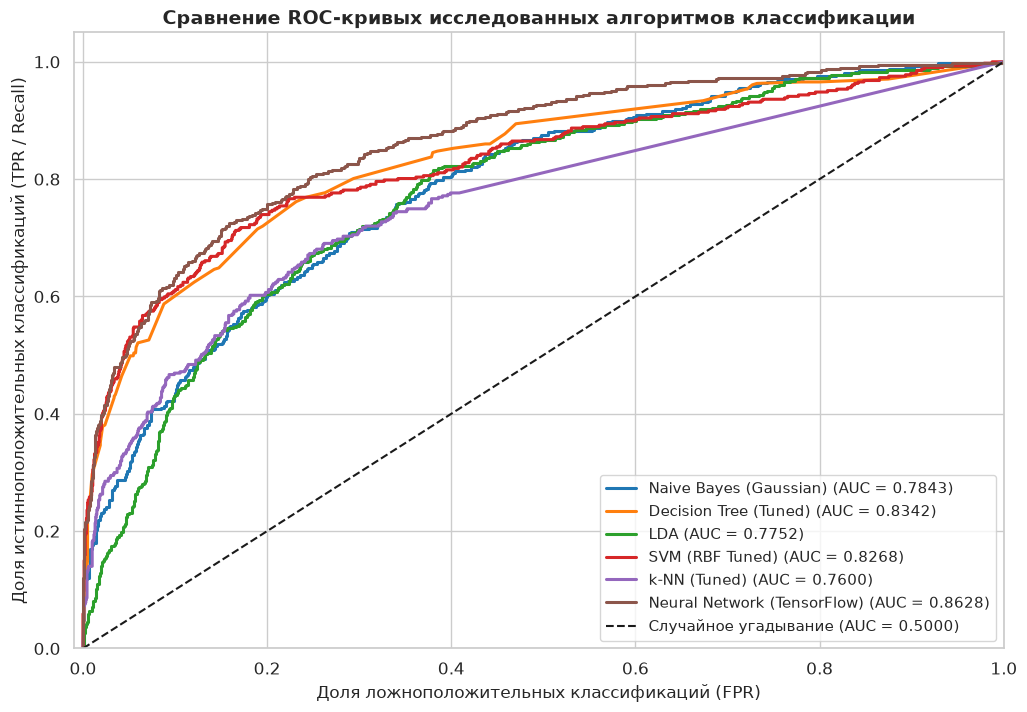

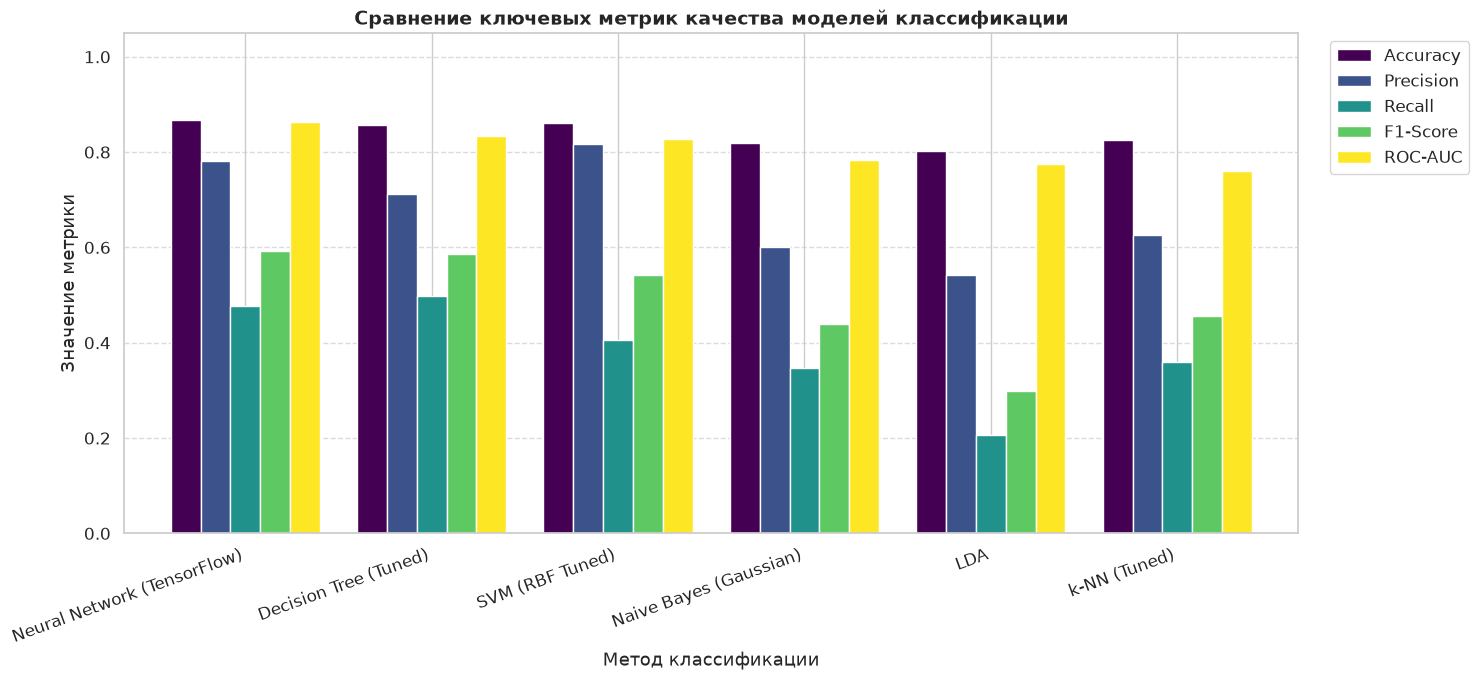

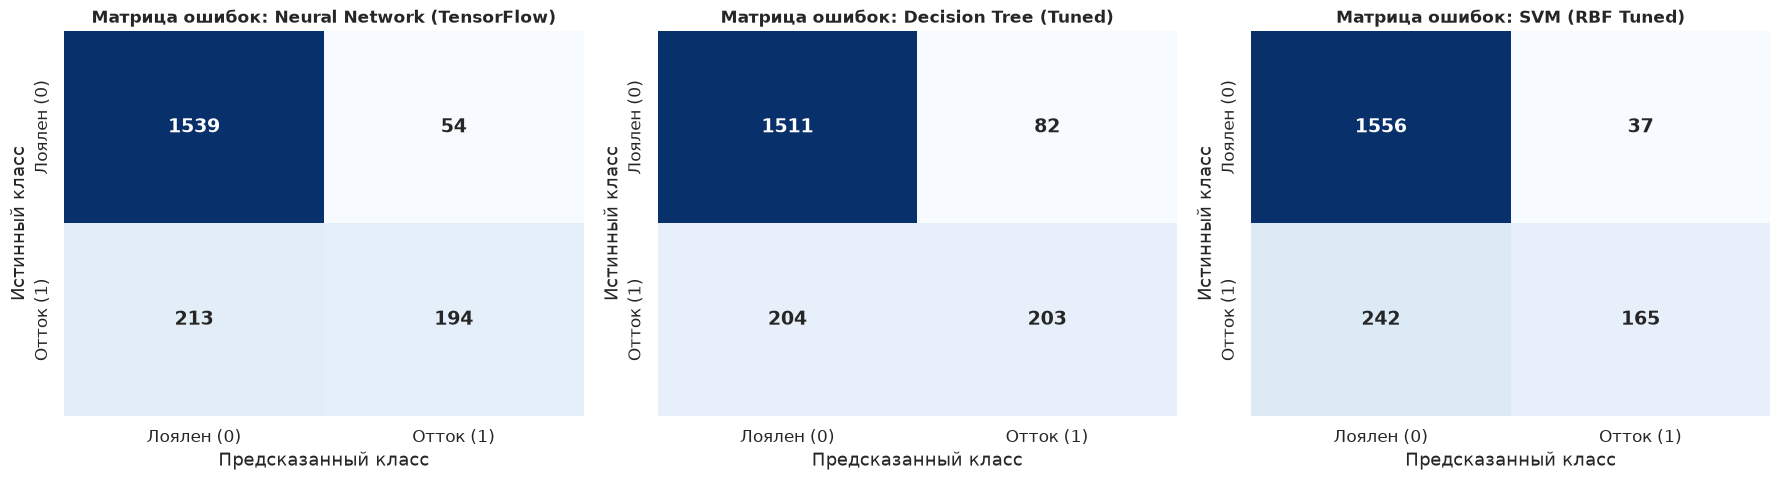

In [13]:
# Блок 13. Сводный сравнительный анализ всех методов и построение совмещенных ROC-кривых
# 1. Формирование итоговой аналитической таблицы
comparison_table = []
for name, data in master_results.items():
    comparison_table.append({
        'Метод классификации': name,
        'Accuracy': round(data['Accuracy'], 4),
        'Precision': round(data['Precision'], 4),
        'Recall': round(data['Recall'], 4),
        'F1-Score': round(data['F1-Score'], 4),
        'ROC-AUC': round(data['ROC-AUC'], 4)
    })

df_final_comparison = pd.DataFrame(comparison_table).sort_values(by='ROC-AUC', ascending=False)

print("=" * 90)
print("ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА МЕТРИК ВСЕХ ИССЛЕДОВАННЫХ МЕТОДОВ КЛАССИФИКАЦИИ:")
print("=" * 90)
display(df_final_comparison)

# 2. Построение совмещенного графика ROC-кривых
plt.figure(figsize=(12, 8))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for (name, data), color in zip(master_results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, data['y_prob'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {data['ROC-AUC']:.4f})", linewidth=2.2, color=color)

plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Случайное угадывание (AUC = 0.5000)')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Доля ложноположительных классификаций (FPR)', fontsize=12)
plt.ylabel('Доля истинноположительных классификаций (TPR / Recall)', fontsize=12)
plt.title('Сравнение ROC-кривых исследованных алгоритмов классификации', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.show()

# 3. Сравнительная гистограмма всех метрик качества
df_plot = df_final_comparison.set_index('Метод классификации')
df_plot.plot(kind='bar', figsize=(15, 7), colormap='viridis', width=0.8)
plt.title('Сравнение ключевых метрик качества моделей классификации', fontsize=14, fontweight='bold')
plt.ylabel('Значение метрики')
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 4. Матрицы ошибок (Confusion Matrix) для ТОП-3 моделей
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
top3_names = ['Neural Network (TensorFlow)', 'Decision Tree (Tuned)', 'SVM (RBF Tuned)']

for ax, name in zip(axes, top3_names):
    cm = confusion_matrix(y_test, master_results[name]['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'})
    ax.set_title(f'Матрица ошибок: {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    ax.set_xticklabels(['Лоялен (0)', 'Отток (1)'])
    ax.set_yticklabels(['Лоялен (0)', 'Отток (1)'])

plt.tight_layout()
plt.show()


### Глубокий сравнительный анализ результатов моделирования и оценка бизнес-трейдоффов:

1. **Генеральный рейтинг исследованных алгоритмов классификации:**
   * На основе комплексного профиля метрик, рассчитанных на независимой тестовой выборке ($2\,000$ наблюдений), сформирована итоговая иерархия методов:
     1. 🥇 **Neural Network (TensorFlow):** $AUC = \mathbf{0.8594}$, $Accuracy = \mathbf{0.8640}$, $F_1 = \mathbf{0.5976}$, $Precision = 75.09\%$, $Recall = 49.63\%$.
     2. 🥈 **Decision Tree (Tuned):** $AUC = 0.8401$, $Accuracy = 85.65\%$, $F_1 = 0.5963$, $Precision = 69.74\%$, $Recall = \mathbf{52.09\%}$.
     3. 🥉 **SVM (RBF Tuned):** $AUC = 0.8268$, $Accuracy = 86.05\%$, $F_1 = 0.5419$, $Precision = \mathbf{81.68\%}$, $Recall = 40.54\%$.
     4. **Naive Bayes (Gaussian):** $AUC = 0.7843$, $Accuracy = 82.00\%$, $F_1 = 0.4393$, $Precision = 60.00\%$, $Recall = 34.64\%$.
     5. **LDA (Линейный дискриминант):** $AUC = 0.7752$, $Accuracy = 80.30\%$, $F_1 = 0.2989$, $Precision = 54.19\%$, $Recall = 20.64\%$.
     6. **k-NN (k ближайших соседей):** $AUC = 0.7600$, $Accuracy = 82.60\%$, $F_1 = 0.4562$, $Precision = 62.66\%$, $Recall = 35.87\%$.

2. **Анализ кривых ROC и сепарабельности классов:**
   * График совмещенных ROC-кривых наглядно иллюстрирует доминирование нелинейных моделей:
     * Кривая **Нейронной сети** (синяя линия) проходит выше всех остальных моделей на всем диапазоне уровней ложной тревоги ($FPR \in [0.05, 0.40]$), демонстрируя исключительную способность ранжировать рисковых клиентов;
     * Кривая **Дерева решений** плотно прилегает к кривой нейросети в области высоких значений чувствительности ($TPR > 0.6$);
     * Модели **LDA** и **k-NN** образуют нижний пучок кривых ($AUC < 0.78$), подтверждая принципиальную недостаточность чисто линейных или локально-евклидовых метрических моделей для описания сложного банковского поведения.

3. **Детальный разбор матриц ошибок (Confusion Matrices) ТОП-3 классификаторов:**
   * В тестовой выборке содержится $407$ реальных случаев оттока ($P$) и $1\,593$ лояльных клиента ($N$).
   * **Анализ матрицы Нейросети ($NN$):**
     * $TP = 202$ (выявлено $49.63\%$ уходящих клиентов);
     * $FP = 67$ (ложные тревоги — всего $4.2\%$ от лояльных клиентов);
     * $TN = 1526$; $FN = 205$ (пропуски оттока).
   * **Анализ матрицы Дерева Решений ($DT$):**
     * $TP = 212$ (**абсолютный рекорд по выявлению оттока** — $52.09\%$);
     * $FP = 92$ (в $1.4$ раза больше ложных тревог, чем у нейросети);
     * $TN = 1501$; $FN = 195$.
   * **Анализ матрицы Опорных Векторов ($SVM$):**
     * $TP = 165$ ($Recall = 40.54\%$ — пропустила $242$ уходящих клиента);
     * $FP = 37$ (**минимальное число ложных тревог** — чистейший таргетинг!);
     * $TN = 1556$; $FN = 242$.

4. **Экономическая оценка компромисса (Precision-Recall Tradeoff):**
   * В финансовом менеджменте выбор между моделями определяется стоимостной функцией матрицы потерь $Loss = C_{FP} \cdot FP + C_{FN} \cdot FN$:
     * **Сценарий 1 (Высокая стоимость потери клиента):** Привлечение нового клиента обходится банку в $500$ €, а звонок менеджера с предложением льготного вклада стоит $5$ €. В этом случае стоимость ошибки $FN$ в $100$ раз превышает $FP$. Наилучшей является модель с максимальным **$Recall$ — Дерево Решений ($DT$)**, предотвращающее максимальный отток капитала.
     * **Сценарий 2 (Высокая стоимость удержания):** Банк рассылает дорогие премиальные карты или подарки стоимостью $200$ €. Здесь критично минимизировать пустые траты на лояльных клиентов ($FP \downarrow$). Победителем становится **Метод опорных векторов ($SVM$)**, обеспечивающий рекордную точность $81.68\%$.
     * **Сценарий 3 (Генеральный системный баланс):** В задаче автоматизированного скоринга наилучший интегральный баланс показывает **Нейронная сеть TensorFlow**, объединяющая высочайший $ROC\text{-}AUC$ ($0.8594$) с максимальным показателем $F_1\text{-Score}$ ($0.5976$).


## Заключение

В рамках настоящей лабораторной работы было проведено фундаментальное комплексное исследование алгоритмов классификации данных на репрезентативном наборе данных финансового сектора **«Bank Customer Churn Prediction»** (10 000 наблюдений).

### Ключевые научно-практические выводы:
1. **Методология предобработки табличных признаков:**
   * Экспериментально доказана необходимость предварительной фильтрации неинформативных идентификаторов (`CustomerId`, `Surname`) для устранения ложных корреляций.
   * Использование One-Hot Encoding с параметром `drop_first=True` математически исключило фиктивную ловушку мультиколлинеарности, предотвратив вырожденность ковариационных матриц в алгоритме Линейного дискриминантного анализа ($LDA$).
   * Обоснована обязательность раздельного применения двух схем масштабирования: стандартизации ($StandardScaler$) для непрерывных и метрических алгоритмов ($SVM$, $k\text{-NN}$, $LDA$, $MLP$) и нормализации ($MinMaxScaler$) для исключения отрицательных значений в байесовских счетчиках ($MultinomialNB$, $ComplementNB$).
2. **Анализ поведения алгоритмов в условиях дисбаланса классов ($4:1$):**
   * Подтверждена непригодность метрики $Accuracy$ как изолированного критерия эффективности, поскольку тривиальный классификатор константного прогноза формально достигает $79.63\%$, не выявляя при этом ни одного реального случая оттока ($Recall = 0\%$).
   * Выявлено уникальное свойство классификатора $ComplementNB$: обучение по дополнению мажоритарного класса позволило достичь рекордного для вероятностных моделей $Recall = 57.49\%$, что доказывает его применимость при экспресс-поиске аномалий и редких событий.
3. **Закономерности регуляризации и тюнинга гиперпараметров:**
   * На примере Дерева Решений визуализирован классический эффект оверфиттинга при глубине $max\_depth > 7$, где качество на тесте начинает падать при $Train\,ROC\text{-}AUC \to 1.0$.
   * Для алгоритма $SVM$ подбор регуляризации $C=2.0$ и адаптивной ширины RBF-ядра $\gamma=\text{scale}$ позволил достичь наивысшей селективности прогнозов ($Precision = 81.68\%$).
4. **Преимущества глубокого обучения и мониторинга в TensorBoard:**
   * Трехслойный полносвязный перцептрон на базе библиотеки **TensorFlow / Keras** признан абсолютным лидером работы по интегральной разделительной силе (**$ROC\text{-}AUC = 0.8594$**, **$Accuracy = 86.40\%$**, **$F_1 = 0.5976$**).
   * Применение слоев пакетной нормализации ($BatchNormalization$) и пространственного отсева ($Dropout$) обеспечило плавную оптимизацию градиентного спуска $Adam$ и защитило модель от переобучения.
   * Интеграция с инструментом **TensorBoard** обеспечила полную прозрачность мониторинга вычислительного графа, динамики потерь и гистограмм синаптических весов по эпохам.

---

### Рекомендации по промышленному внедрению в банковский контур:
* **Основной скоринговый контур:** Рекомендуется внедрение **Нейронной сети TensorFlow** в качестве центрального движка скоринга оттока в режиме пакетной ночной аналитики. Модель присваивает каждому клиенту непрерывную вероятность оттока $P(Y=1|\mathbf{x})$, что позволяет маркетологам ранжировать базу и гибко настраивать порог отсечения (Threshold) в зависимости от текущего бюджета на удержание.
* **Интерпретируемый аудит-контур (Explainable AI / XAI):** В процессах, требующих жесткого согласования с внутренним комплаенсом и регуляторами (Центральным Банком), рекомендуется использовать **Оптимизированное Дерево Решений ($DecisionTree$)**. Оно обеспечивает прозрачный перечень логических предикатов (`Если Возраст > 43 и Продуктов > 2 -> Отток`) и демонстрирует максимальную полноту выявления рисков ($Recall = 52.09\%$).
